# Predicting Diabetes Disease Progression
### A regression study of feature engineering, model complexity and regularization (OLS, Ridge, Lasso)

**Dataset:** `sklearn.datasets.load_diabetes` — 442 patients, 10 baseline features, continuous target (disease progression one year after baseline).

**Central question:** *How do feature engineering, model complexity, and regularization affect the ability of OLS, Ridge, and Lasso regression to predict diabetes disease progression?*

The goal is to build and evaluate regression models that predict a quantitative measure of diabetes disease progression one year after baseline measurement, using the load_diabetes dataset from scikit-learn.

This is a regression problem — not classification. The target variable y is continuous.

We learn a function:

f : R¹⁰ → R
such that ŷ = f(x)

where x ∈ R¹⁰ are the 10 baseline patient features and ŷ is the predicted disease progression score.

In [31]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)

**1. Data loading**

In [32]:
data = load_diabetes(as_frame=True)
df = data.frame.copy()
FEATURES = data.feature_names
print(df.shape)
print(f"Samples:  {df.shape[0]}")
print(f"Features: {df.shape[1]}")
print(f"Target range: {df['target'].min():.1f} – {df['target'].max():.1f}")
print(f"Target mean:  {df['target'].mean():.1f}")
print(f"Target std:   {df['target'].std():.1f}")

(442, 11)
Samples:  442
Features: 11
Target range: 25.0 – 346.0
Target mean:  152.1
Target std:   77.1


In [33]:
print("=" * 60)
print("1. DATASET OVERVIEW")
print("=" * 60)

# Shape
print(f"\nShape: {df.shape}")
print(f"   Rows (patients): {df.shape[0]}")
print(f"   Columns (features + target): {df.shape[1]}")

# Data types
print(f"\n Data Types:")
print(df.dtypes)

# First 5 rows
print(f"\nFirst 5 Rows:")
display(df.head())

# Last 5 rows
print(f"\n Last 5 Rows:")
display(df.tail())

# Random sample
print(f"\n Random Sample (5 rows):")
display(df.sample(5, random_state=42))

1. DATASET OVERVIEW

Shape: (442, 11)
   Rows (patients): 442
   Columns (features + target): 11

 Data Types:
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

First 5 Rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176,151.0
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922,75.0
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259,141.0
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094,206.0
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466,135.0



 Last 5 Rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
437,0.0417,0.0507,0.0197,0.0597,-0.0057,-0.0026,-0.0287,-0.0026,0.0312,0.0072,178.0
438,-0.0055,0.0507,-0.0159,-0.0676,0.0493,0.0792,-0.0287,0.0343,-0.0181,0.0445,104.0
439,0.0417,0.0507,-0.0159,0.0173,-0.0373,-0.0138,-0.0250,-0.0111,-0.0469,0.0155,132.0
440,-0.0455,-0.0446,0.0391,0.0012,0.0163,0.0153,-0.0287,0.0266,0.0445,-0.0259,220.0
441,-0.0455,-0.0446,-0.0730,-0.0814,0.0837,0.0278,0.1738,-0.0395,-0.0042,0.0031,57.0



 Random Sample (5 rows):


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
287,0.0453,-0.0446,-0.0062,-0.0160,0.1250,0.1252,0.0192,0.0343,0.0324,-0.0052,219.0
211,0.0926,-0.0446,0.0369,0.0219,-0.0250,-0.0167,0.0008,-0.0395,-0.0225,-0.0218,70.0
72,0.0635,0.0507,-0.0041,-0.0126,0.1030,0.0488,0.0560,-0.0026,0.0845,-0.0176,202.0
321,0.0962,-0.0446,0.0520,0.0793,0.0548,0.0366,-0.0765,0.1413,0.0986,0.0611,230.0
73,0.0126,0.0507,-0.0202,-0.0022,0.0383,0.0532,-0.0066,0.0343,-0.0051,-0.0094,111.0


In [34]:
feature_info = pd.DataFrame({
    'Feature': ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6'],
    'Description': [
        'Age in years',
        'Biological sex',
        'Body Mass Index',
        'Average blood pressure',
        'Total cholesterol (tc)',
        'LDL cholesterol (ldl)',
        'HDL cholesterol (hdl)',
        'TCH ratio (tch)',
        'Log triglycerides (ltg)',
        'Blood sugar level (glu)'
    ],
    'Clinical Relevance': [
        'Risk increases with age',
        'Hormonal influence',
        'Strongest predictor',
        'Cardiovascular link',
        'Lipid metabolism',
        'Bad cholesterol',
        'Good cholesterol',
        'Total/HDL ratio',
        'Metabolic marker',
        'Direct glucose link'
    ]
})
styled = feature_info.style \
    .set_caption("Dataset Features — All pre-standardized (mean=0, std=1)") \
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '14px'),
                   ('font-weight', 'bold'),
                   ('color', '#333')]},
        {'selector': 'th',
         'props': [('background-color', '#4472C4'),
                   ('color', 'white'),
                   ('font-size', '12px'),
                   ('text-align', 'center'),
                   ('padding', '8px')]},
        {'selector': 'td',
         'props': [('text-align', 'left'),
                   ('padding', '6px'),
                   ('font-size', '12px')]},
    ]) \
    .apply(lambda x: [
        'background-color: #D9E1F2' if i % 2 == 0
        else 'background-color: #FFFFFF'
        for i in range(len(x))
    ], axis=0) \
    .highlight_between(subset=['Feature'],
                       props='font-weight: bold; color: #1F3864;')

display(styled)

,Feature,Description,Clinical Relevance
0,age,Age in years,Risk increases with age
1,sex,Biological sex,Hormonal influence
2,bmi,Body Mass Index,Strongest predictor
3,bp,Average blood pressure,Cardiovascular link
4,s1,Total cholesterol (tc),Lipid metabolism
5,s2,LDL cholesterol (ldl),Bad cholesterol
6,s3,HDL cholesterol (hdl),Good cholesterol
7,s4,TCH ratio (tch),Total/HDL ratio
8,s5,Log triglycerides (ltg),Metabolic marker
9,s6,Blood sugar level (glu),Direct glucose link


**2. MISSING VALUES ANALYSIS**

2. MISSING VALUES ANALYSIS
        Missing Count  Missing %
age                 0        0.0
sex                 0        0.0
bmi                 0        0.0
bp                  0        0.0
s1                  0        0.0
s2                  0        0.0
s3                  0        0.0
s4                  0        0.0
s5                  0        0.0
s6                  0        0.0
target              0        0.0


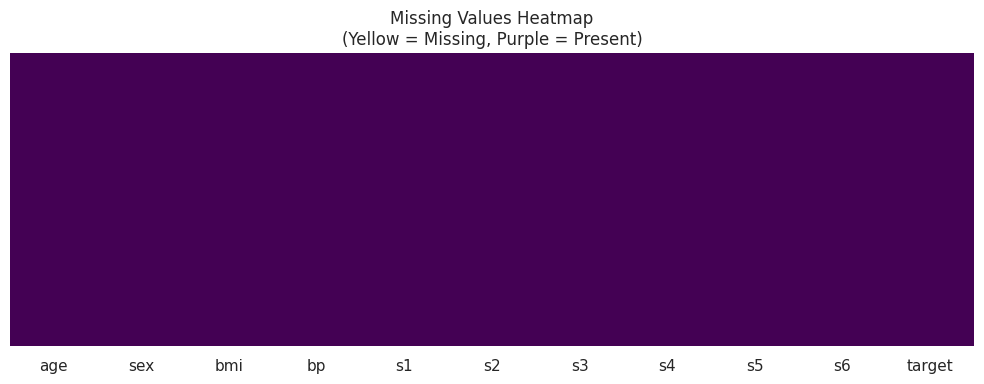


 Result: No missing values in this dataset


In [35]:
print("=" * 60)
print("2. MISSING VALUES ANALYSIS")
print("=" * 60)

missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct.round(2)
})
print(missing_df)

plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(),
            yticklabels=False,
            cbar=False,
            cmap='viridis')
plt.title('Missing Values Heatmap\n(Yellow = Missing, Purple = Present)')
plt.tight_layout()
plt.show()

print("\n Result: No missing values in this dataset")

**3. DESCRIPTIVE STATISTICS**

In [36]:
print("=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)

# Full stats
desc = df.describe().T
desc['range']   = desc['max'] - desc['min']
desc['cv']      = (desc['std'] / desc['mean']).round(4)  # coefficient of variation
display(desc.round(4))

# Extended stats including skewness & kurtosis
ext_stats = pd.DataFrame({
    'Mean':     df.mean().round(4),
    'Median':   df.median().round(4),
    'Std':      df.std().round(4),
    'Variance': df.var().round(4),
    'Min':      df.min().round(4),
    'Max':      df.max().round(4),
    'Range':    (df.max() - df.min()).round(4),
    'Skewness': df.skew().round(4),
    'Kurtosis': df.kurt().round(4),
    'IQR':      (df.quantile(0.75) - df.quantile(0.25)).round(4)
})

print("=" * 60)
print("\n Extended Statistics:")
print("=" * 60)
display(ext_stats)

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max,range,cv
age,442.0,-0.0000,0.0476,-0.1072,-0.0373,0.0054,0.0381,0.1107,0.2180,-1.8958e+17
sex,442.0,0.0000,0.0476,-0.0446,-0.0446,-0.0446,0.0507,0.0507,0.0953,3.8690e+15
bmi,442.0,-0.0000,0.0476,-0.0903,-0.0342,-0.0073,0.0312,0.1706,0.2608,-2.1206e+14
bp,442.0,-0.0000,0.0476,-0.1124,-0.0367,-0.0057,0.0356,0.1320,0.2444,-9.9257e+14
s1,442.0,-0.0000,0.0476,-0.1268,-0.0342,-0.0043,0.0284,0.1539,0.2807,-3.4469e+15
s2,442.0,0.0000,0.0476,-0.1156,-0.0304,-0.0038,0.0298,0.1988,0.3144,1.2153e+15
s3,442.0,-0.0000,0.0476,-0.1023,-0.0351,-0.0066,0.0293,0.1812,0.2835,-8.2426e+15
s4,442.0,-0.0000,0.0476,-0.0764,-0.0395,-0.0026,0.0343,0.1852,0.2616,-5.2661e+15
s5,442.0,0.0000,0.0476,-0.1261,-0.0332,-0.0019,0.0324,0.1336,0.2597,5.1238e+14
s6,442.0,0.0000,0.0476,-0.1378,-0.0332,-0.0011,0.0279,0.1356,0.2734,4.2129e+15



 Extended Statistics:


,Mean,Median,Std,Variance,Min,Max,Range,Skewness,Kurtosis,IQR
age,-0.0000,0.0054,0.0476,0.0023,-0.1072,0.1107,0.2180,-0.2314,-0.6712,0.0754
sex,0.0000,-0.0446,0.0476,0.0023,-0.0446,0.0507,0.0953,0.1274,-1.9928,0.0953
bmi,-0.0000,-0.0073,0.0476,0.0023,-0.0903,0.1706,0.2608,0.5981,0.0951,0.0655
bp,-0.0000,-0.0057,0.0476,0.0023,-0.1124,0.1320,0.2444,0.2907,-0.5328,0.0723
s1,-0.0000,-0.0043,0.0476,0.0023,-0.1268,0.1539,0.2807,0.3781,0.2329,0.0626
s2,0.0000,-0.0038,0.0476,0.0023,-0.1156,0.1988,0.3144,0.4366,0.6014,0.0602
s3,-0.0000,-0.0066,0.0476,0.0023,-0.1023,0.1812,0.2835,0.7993,0.9815,0.0644
s4,-0.0000,-0.0026,0.0476,0.0023,-0.0764,0.1852,0.2616,0.7354,0.4444,0.0738
s5,0.0000,-0.0019,0.0476,0.0023,-0.1261,0.1336,0.2597,0.2918,-0.1344,0.0657
s6,0.0000,-0.0011,0.0476,0.0023,-0.1378,0.1356,0.2734,0.2079,0.2369,0.0611


**4. TARGET VARIABLE ANALYSIS**

4. TARGET VARIABLE ANALYSIS


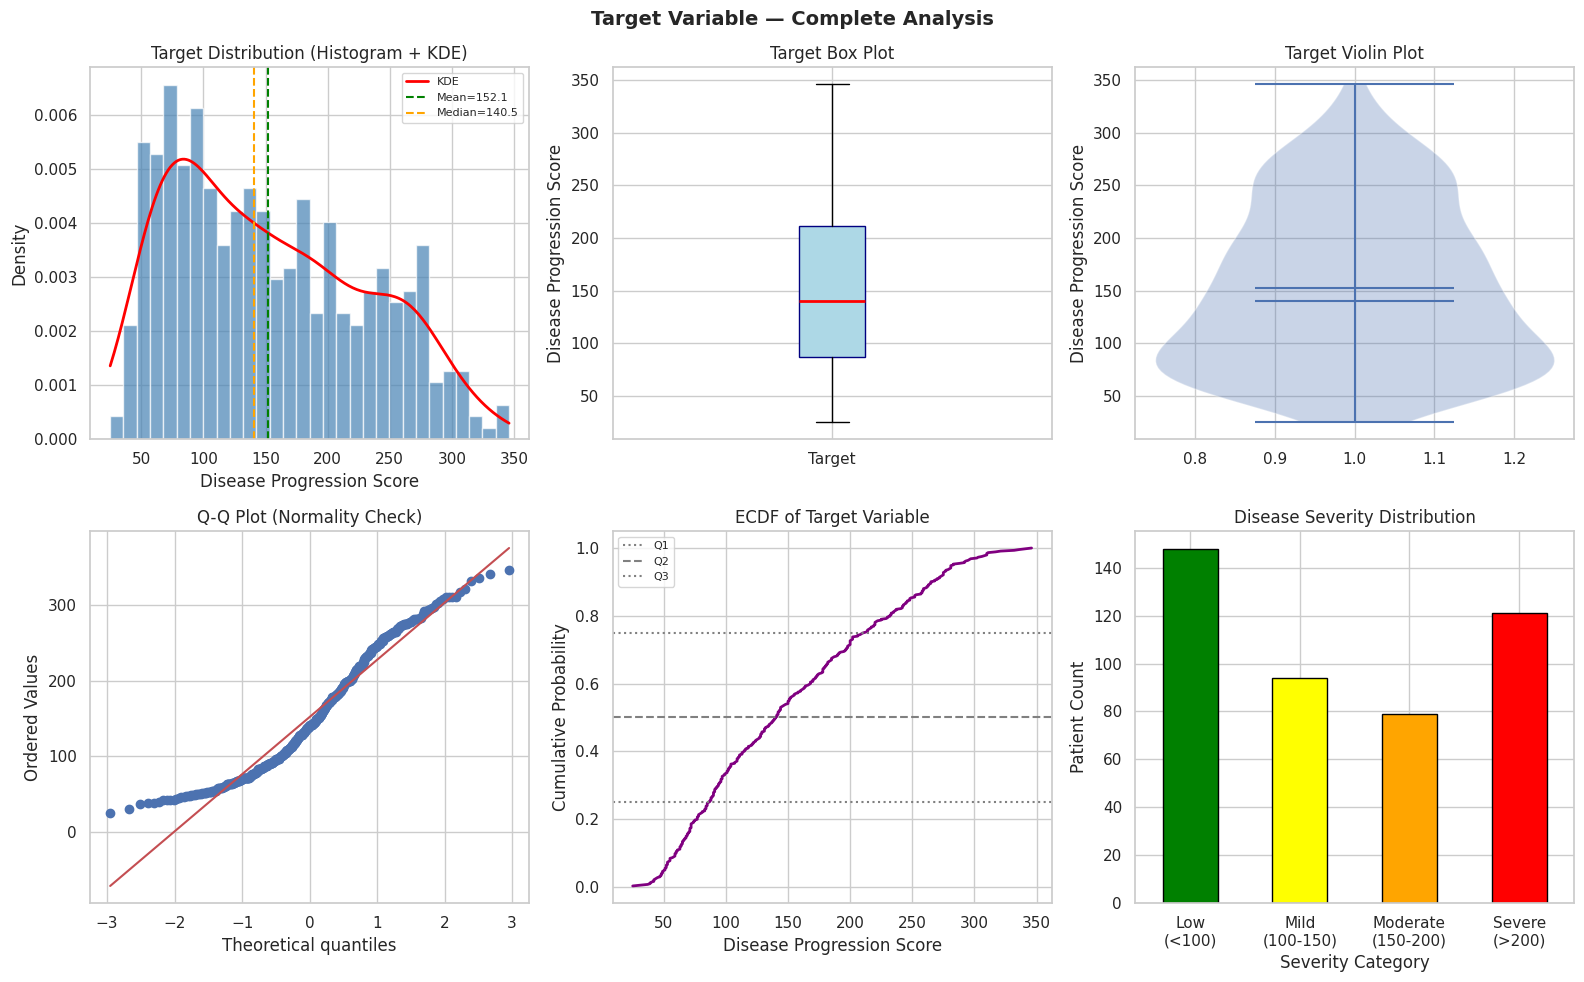


 Normality Tests:
   Shapiro-Wilk:  statistic=0.9491, p=0.0000
   D'Agostino:    statistic=64.1509, p=0.0000
   Skewness:      0.4391
   Kurtosis:      -0.8866

   Mean:   152.13
   Median: 140.50
   Std:    77.09
   Min:    25.00
   Max:    346.00


In [37]:
from scipy import stats
from scipy.stats import shapiro, normaltest, skew, kurtosis
from sklearn.datasets import load_diabetes

# Load dataset and define df and y to make cell self-contained
data = load_diabetes(as_frame=True)
df = data.frame.copy()
y = df['target']

print("=" * 60)
print("4. TARGET VARIABLE ANALYSIS")
print("=" * 60)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 4.1 Histogram with KDE
axes[0,0].hist(y, bins=30, color='steelblue',
               edgecolor='white', alpha=0.7, density=True)
axes[0,0].set_title('Target Distribution (Histogram + KDE)')
axes[0,0].set_xlabel('Disease Progression Score')
axes[0,0].set_ylabel('Density')
# Add KDE
from scipy.stats import gaussian_kde
kde = gaussian_kde(y)
x_range = np.linspace(y.min(), y.max(), 200)
axes[0,0].plot(x_range, kde(x_range), color='red', lw=2, label='KDE')
axes[0,0].axvline(y.mean(),   color='green', ls='--', lw=1.5, label=f'Mean={y.mean():.1f}')
axes[0,0].axvline(np.median(y), color='orange', ls='--', lw=1.5, label=f'Median={np.median(y):.1f}')
axes[0,0].legend(fontsize=8)

# 4.2 Box plot
axes[0,1].boxplot(y, patch_artist=True,
                  boxprops=dict(facecolor='lightblue', color='navy'),
                  medianprops=dict(color='red', linewidth=2))
axes[0,1].set_title('Target Box Plot')
axes[0,1].set_ylabel('Disease Progression Score')
axes[0,1].set_xticks([1])
axes[0,1].set_xticklabels(['Target'])

# 4.3 Violin plot
axes[0,2].violinplot(y, showmeans=True, showmedians=True)
axes[0,2].set_title('Target Violin Plot')
axes[0,2].set_ylabel('Disease Progression Score')

# 4.4 Q-Q plot (normality check)
stats.probplot(y, dist="norm", plot=axes[1,0])
axes[1,0].set_title('Q-Q Plot (Normality Check)')

# 4.5 ECDF
sorted_y = np.sort(y)
ecdf     = np.arange(1, len(sorted_y)+1) / len(sorted_y)
axes[1,1].plot(sorted_y, ecdf, color='purple', lw=2)
axes[1,1].set_title('ECDF of Target Variable')
axes[1,1].set_xlabel('Disease Progression Score')
axes[1,1].set_ylabel('Cumulative Probability')
axes[1,1].axhline(0.25, color='grey', ls=':', label='Q1')
axes[1,1].axhline(0.50, color='grey', ls='--', label='Q2')
axes[1,1].axhline(0.75, color='grey', ls=':', label='Q3')
axes[1,1].legend(fontsize=8)

# 4.6 Target binned (disease severity)
bins   = [0, 100, 150, 200, 350]
labels = ['Low\n(<100)', 'Mild\n(100-150)', 'Moderate\n(150-200)', 'Severe\n(>200)']
y_bins = pd.cut(y, bins=bins, labels=labels)
y_bins.value_counts().sort_index().plot(
    kind='bar', ax=axes[1,2],
    color=['green', 'yellow', 'orange', 'red'],
    edgecolor='black'
)
axes[1,2].set_title('Disease Severity Distribution')
axes[1,2].set_xlabel('Severity Category')
axes[1,2].set_ylabel('Patient Count')
axes[1,2].tick_params(axis='x', rotation=0)

plt.suptitle('Target Variable — Complete Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Statistical tests for normality
stat_sw, p_sw = shapiro(y)
stat_nt, p_nt = normaltest(y)
print(f"\n Normality Tests:")
print(f"   Shapiro-Wilk:  statistic={stat_sw:.4f}, p={p_sw:.4f}")
print(f"   D'Agostino:    statistic={stat_nt:.4f}, p={p_nt:.4f}")
print(f"   Skewness:      {skew(y):.4f}")
print(f"   Kurtosis:      {kurtosis(y):.4f}")
print(f"\n   Mean:   {y.mean():.2f}")
print(f"   Median: {np.median(y):.2f}")
print(f"   Std:    {y.std():.2f}")
print(f"   Min:    {y.min():.2f}")
print(f"   Max:    {y.max():.2f}")

**5. FEATURE DISTRIBUTIONS**

5. FEATURE DISTRIBUTIONS


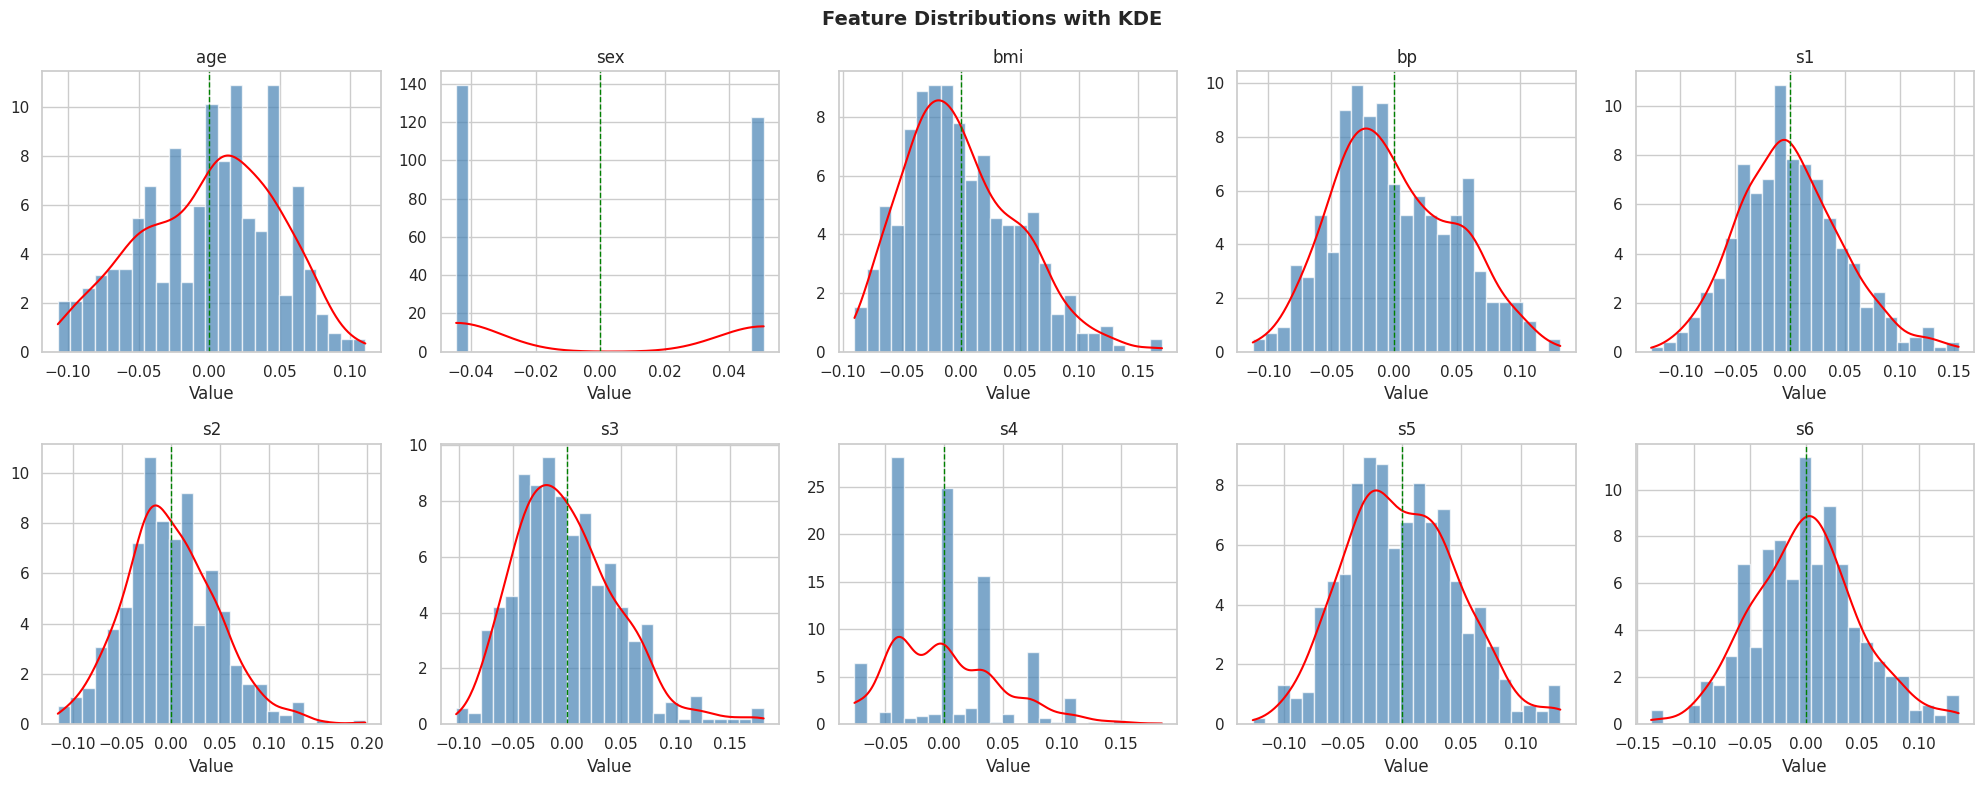

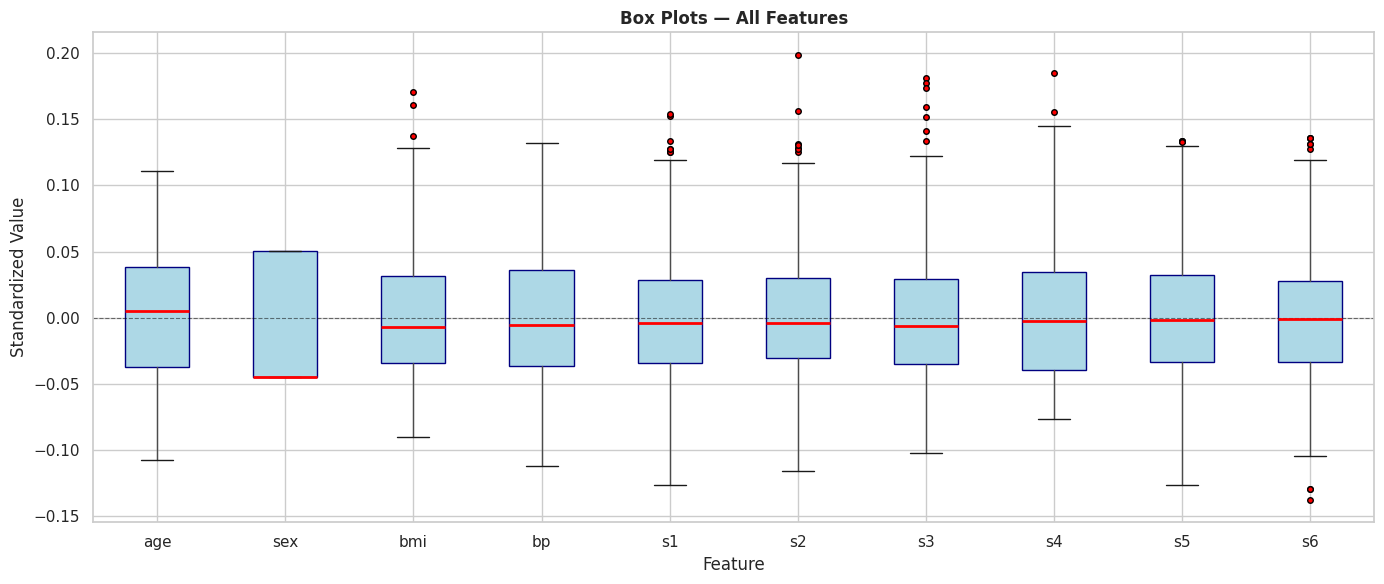

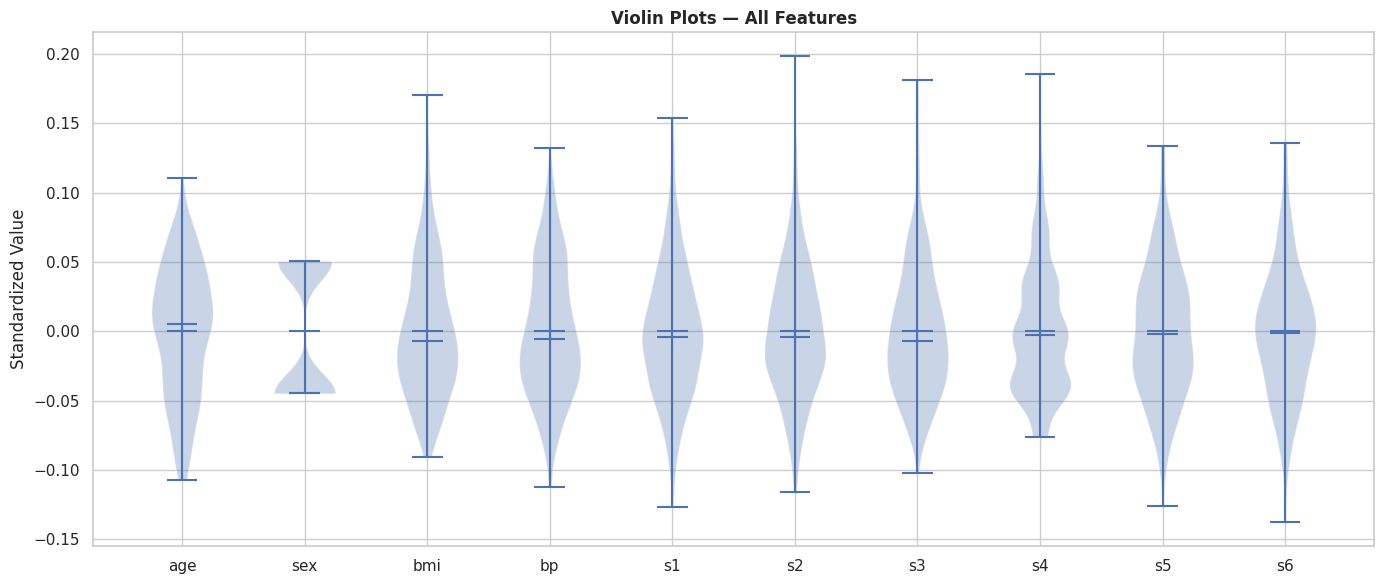

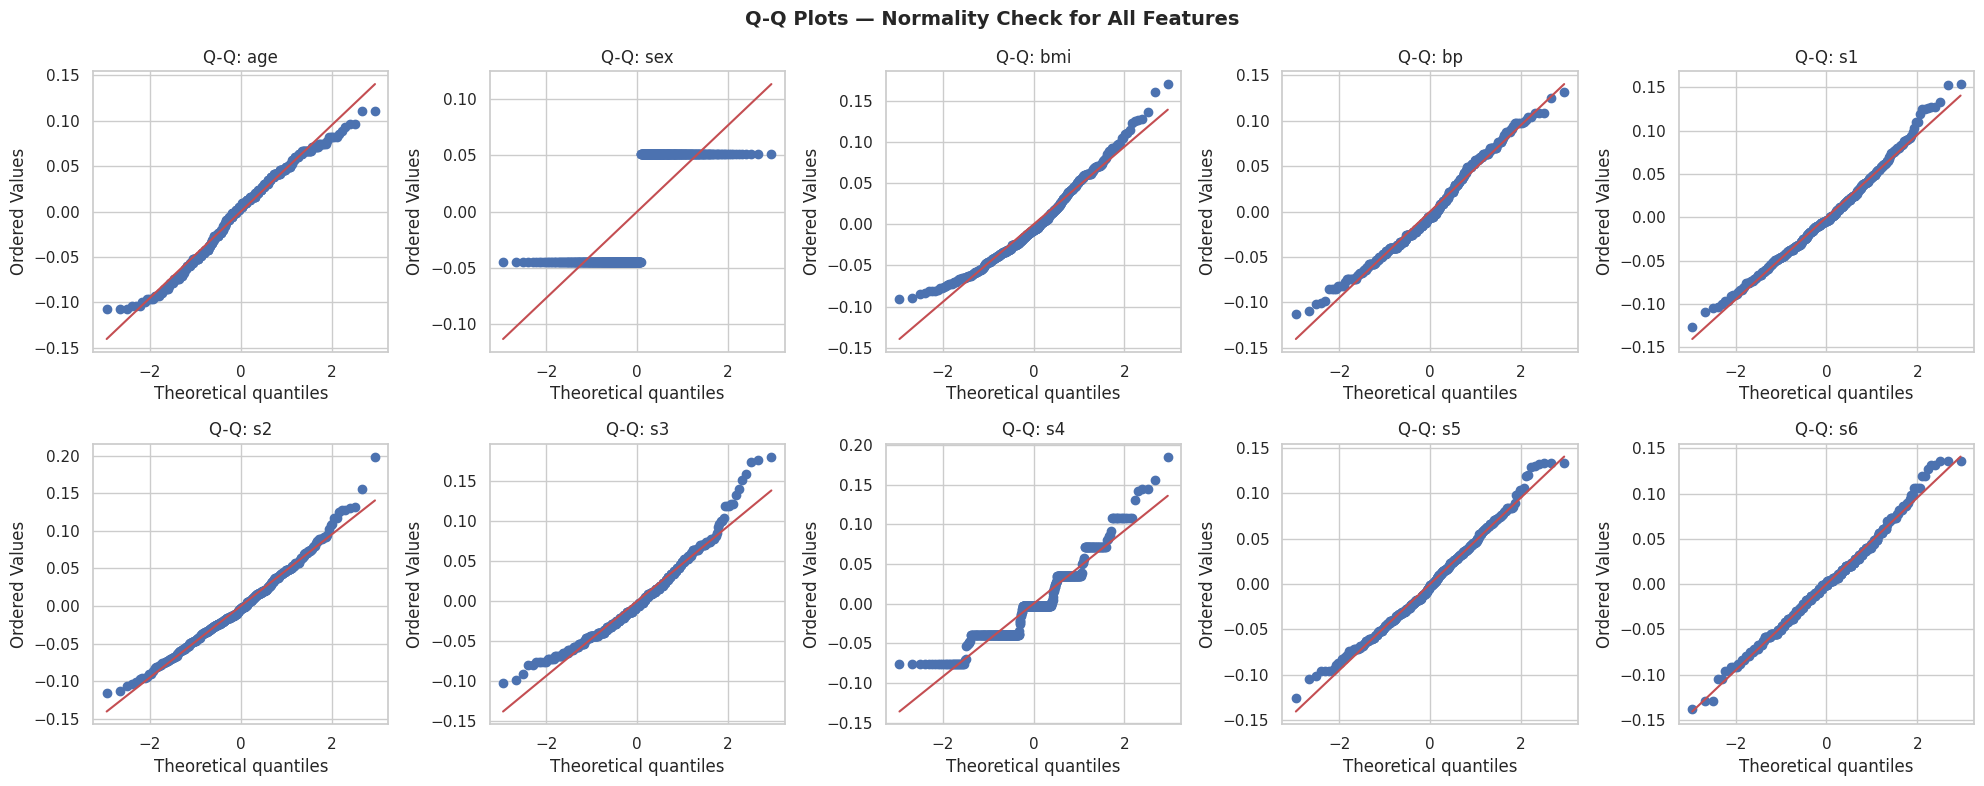

In [38]:
print("=" * 60)
print("5. FEATURE DISTRIBUTIONS")
print("=" * 60)

# 5.1 Histogram for all features
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, feat in enumerate(FEATURES):
    axes[i].hist(df[feat], bins=25, color='steelblue',
                 edgecolor='white', alpha=0.7, density=True)
    # Add KDE
    kde = gaussian_kde(df[feat])
    x_r = np.linspace(df[feat].min(), df[feat].max(), 200)
    axes[i].plot(x_r, kde(x_r), color='red', lw=1.5)
    axes[i].axvline(df[feat].mean(), color='green',
                    ls='--', lw=1, label='Mean')
    axes[i].set_title(f'{feat}')
    axes[i].set_xlabel('Value')

plt.suptitle('Feature Distributions with KDE', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 5.2 Box plots for all features
fig, ax = plt.subplots(figsize=(14, 6))
df[FEATURES].boxplot(ax=ax, patch_artist=True,
    boxprops=dict(facecolor='lightblue', color='navy'),
    medianprops=dict(color='red', linewidth=2),
    flierprops=dict(marker='o', markerfacecolor='red', markersize=4))
ax.axhline(0, color='black', ls='--', lw=0.8, alpha=0.5)
ax.set_title('Box Plots — All Features', fontweight='bold')
ax.set_xlabel('Feature')
ax.set_ylabel('Standardized Value')
plt.tight_layout()
plt.show()

# 5.3 Violin plots for all features
fig, ax = plt.subplots(figsize=(14, 6))
parts = ax.violinplot([df[f].values for f in FEATURES],
                       positions=range(len(FEATURES)),
                       showmeans=True, showmedians=True)
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES)
ax.set_title('Violin Plots — All Features', fontweight='bold')
ax.set_ylabel('Standardized Value')
plt.tight_layout()
plt.show()

# 5.4 Q-Q plots for all features
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()
for i, feat in enumerate(FEATURES):
    stats.probplot(df[feat], dist='norm', plot=axes[i])
    axes[i].set_title(f'Q-Q: {feat}')
plt.suptitle('Q-Q Plots — Normality Check for All Features',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**6. OUTLIER DETECTION**

6. OUTLIER DETECTION

 IQR Outlier Detection:


,Feature,Q1,Q3,IQR,Lower Fence,Upper Fence,Outlier Count,Outlier %
0,age,-0.0373,0.0381,0.0754,-0.1504,0.1511,0,0.00
1,sex,-0.0446,0.0507,0.0953,-0.1876,0.1937,0,0.00
2,bmi,-0.0342,0.0312,0.0655,-0.1324,0.1295,3,0.68
3,bp,-0.0367,0.0356,0.0723,-0.1451,0.1441,0,0.00
4,s1,-0.0342,0.0284,0.0626,-0.1282,0.1223,8,1.81
5,s2,-0.0304,0.0298,0.0602,-0.1207,0.1201,7,1.58
6,s3,-0.0351,0.0293,0.0644,-0.1318,0.1260,7,1.58
7,s4,-0.0395,0.0343,0.0738,-0.1502,0.1450,2,0.45
8,s5,-0.0332,0.0324,0.0657,-0.1318,0.1309,4,0.90
9,s6,-0.0332,0.0279,0.0611,-0.1248,0.1196,9,2.04



 Z-Score Outlier Detection (|z| > 3):


,Feature,Z-score Outliers
0,age,0
1,sex,0
2,bmi,2
3,bp,0
4,s1,2
5,s2,2
6,s3,5
7,s4,4
8,s5,0
9,s6,0


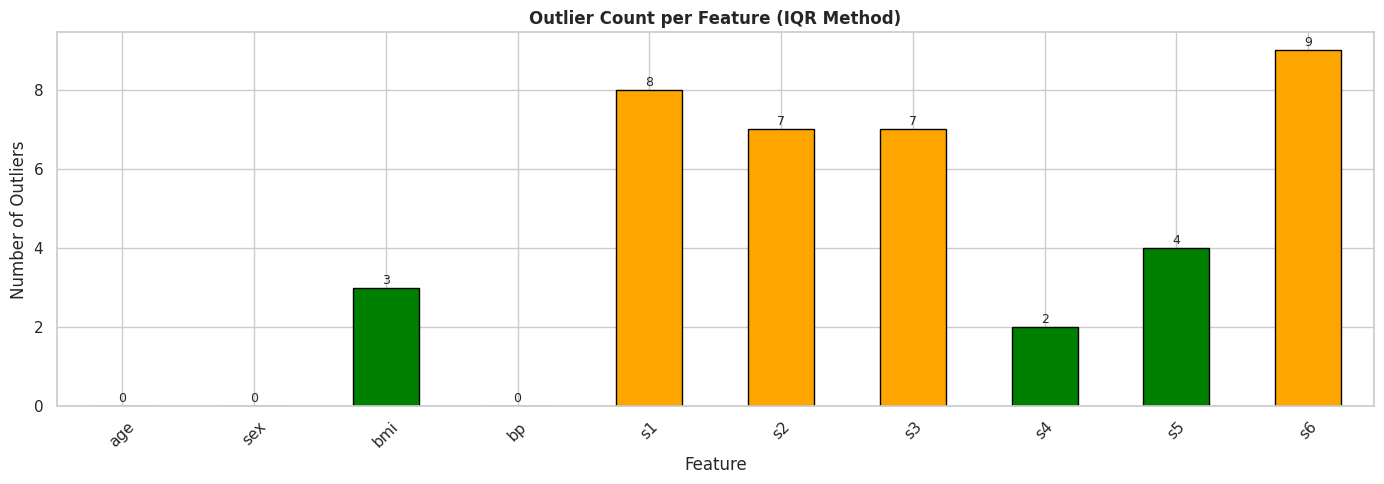

In [39]:
print("=" * 60)
print("6. OUTLIER DETECTION")
print("=" * 60)

# 6.1 IQR method
print("\n IQR Outlier Detection:")
outlier_summary = []
for feat in FEATURES:
    Q1  = df[feat].quantile(0.25)
    Q3  = df[feat].quantile(0.75)
    IQR = Q3 - Q1
    lo  = Q1 - 1.5 * IQR
    hi  = Q3 + 1.5 * IQR
    n_out = ((df[feat] < lo) | (df[feat] > hi)).sum()
    outlier_summary.append({
        'Feature': feat,
        'Q1': round(Q1, 4),
        'Q3': round(Q3, 4),
        'IQR': round(IQR, 4),
        'Lower Fence': round(lo, 4),
        'Upper Fence': round(hi, 4),
        'Outlier Count': n_out,
        'Outlier %': round(n_out / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df)

# 6.2 Z-score method
print("\n Z-Score Outlier Detection (|z| > 3):")
z_scores = np.abs(stats.zscore(df[FEATURES]))
z_outliers = (z_scores > 3).sum(axis=0)
z_df = pd.DataFrame({
    'Feature': FEATURES,
    'Z-score Outliers': z_outliers
})
display(z_df)

# 6.3 Visualise outliers
fig, ax = plt.subplots(figsize=(14, 5))
outlier_counts = outlier_df.set_index('Feature')['Outlier Count']
colors = ['red' if c > 10 else 'orange' if c > 5 else 'green'
          for c in outlier_counts]
outlier_counts.plot(kind='bar', ax=ax, color=colors, edgecolor='black')
ax.set_title('Outlier Count per Feature (IQR Method)', fontweight='bold')
ax.set_xlabel('Feature')
ax.set_ylabel('Number of Outliers')
ax.tick_params(axis='x', rotation=45)
for i, v in enumerate(outlier_counts):
    ax.text(i, v + 0.1, str(v), ha='center', fontsize=9)
plt.tight_layout()
plt.show()

**7. CORRELATION ANALYSIS**

7. CORRELATION ANALYSIS


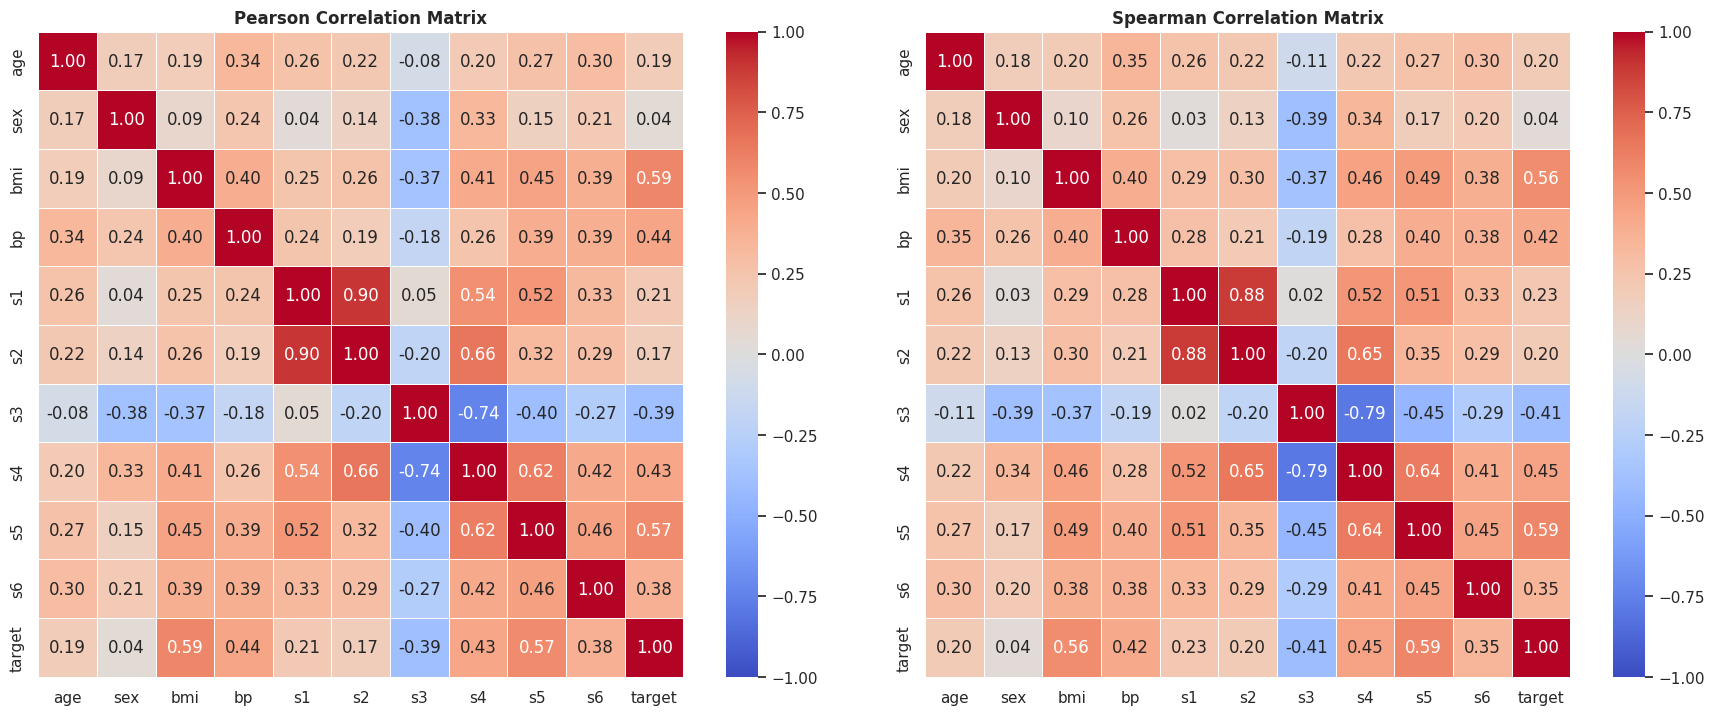


 Feature Correlation with Target (Pearson):
bmi    0.5865
s5     0.5659
bp     0.4415
s4     0.4305
s3    -0.3948
s6     0.3825
s1     0.2120
age    0.1879
s2     0.1741
sex    0.0431
Name: target, dtype: float64


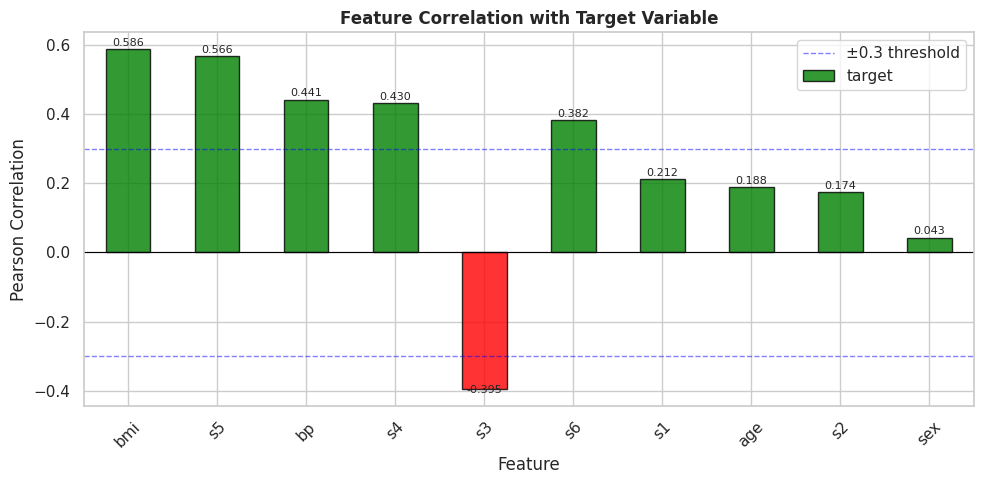


 Highly Correlated Feature Pairs (|r| > 0.5):


,Feature 1,Feature 2,Correlation,Abs Correlation
0,s1,s2,0.8967,0.8967
4,s3,s4,-0.7385,0.7385
3,s2,s4,0.6598,0.6598
5,s4,s5,0.6179,0.6179
1,s1,s4,0.5422,0.5422
2,s1,s5,0.5155,0.5155


In [40]:
print("=" * 60)
print("7. CORRELATION ANALYSIS")
print("=" * 60)

# 7.1 Full correlation matrix — heatmap
corr = df.corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Pearson correlation
sns.heatmap(corr, annot=True, fmt='.2f',
            cmap='coolwarm', center=0,
            vmin=-1, vmax=1,
            ax=axes[0],
            linewidths=0.5,
            square=True)
axes[0].set_title('Pearson Correlation Matrix', fontweight='bold')

# Spearman correlation
corr_sp = df.corr(method='spearman')
sns.heatmap(corr_sp, annot=True, fmt='.2f',
            cmap='coolwarm', center=0,
            vmin=-1, vmax=1,
            ax=axes[1],
            linewidths=0.5,
            square=True)
axes[1].set_title('Spearman Correlation Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

# 7.2 Feature vs Target correlation
target_corr = corr['target'].drop('target').sort_values(key=abs, ascending=False)
print("\n Feature Correlation with Target (Pearson):")
print(target_corr.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['green' if c > 0 else 'red' for c in target_corr]
target_corr.plot(kind='bar', ax=ax, color=colors, edgecolor='black', alpha=0.8)
ax.axhline(0, color='black', lw=0.8)
ax.axhline(0.3, color='blue', ls='--', lw=1, alpha=0.5, label='±0.3 threshold')
ax.axhline(-0.3, color='blue', ls='--', lw=1, alpha=0.5)
ax.set_title('Feature Correlation with Target Variable', fontweight='bold')
ax.set_xlabel('Feature')
ax.set_ylabel('Pearson Correlation')
ax.tick_params(axis='x', rotation=45)
ax.legend()
for i, v in enumerate(target_corr):
    ax.text(i, v + 0.01 * np.sign(v), f'{v:.3f}',
            ha='center', fontsize=8)
plt.tight_layout()
plt.show()

# 7.3 High multicollinearity pairs
print("\n Highly Correlated Feature Pairs (|r| > 0.5):")
feat_corr = corr.drop('target', axis=0).drop('target', axis=1)
high_corr = []
for i in range(len(FEATURES)):
    for j in range(i+1, len(FEATURES)):
        r = feat_corr.iloc[i, j]
        if abs(r) > 0.5:
            high_corr.append({
                'Feature 1': FEATURES[i],
                'Feature 2': FEATURES[j],
                'Correlation': round(r, 4),
                'Abs Correlation': round(abs(r), 4)
            })
high_corr_df = pd.DataFrame(high_corr).sort_values(
    'Abs Correlation', ascending=False)
display(high_corr_df)

**8. FEATURE vs TARGET SCATTER PLOTS**

8. FEATURE vs TARGET RELATIONSHIPS


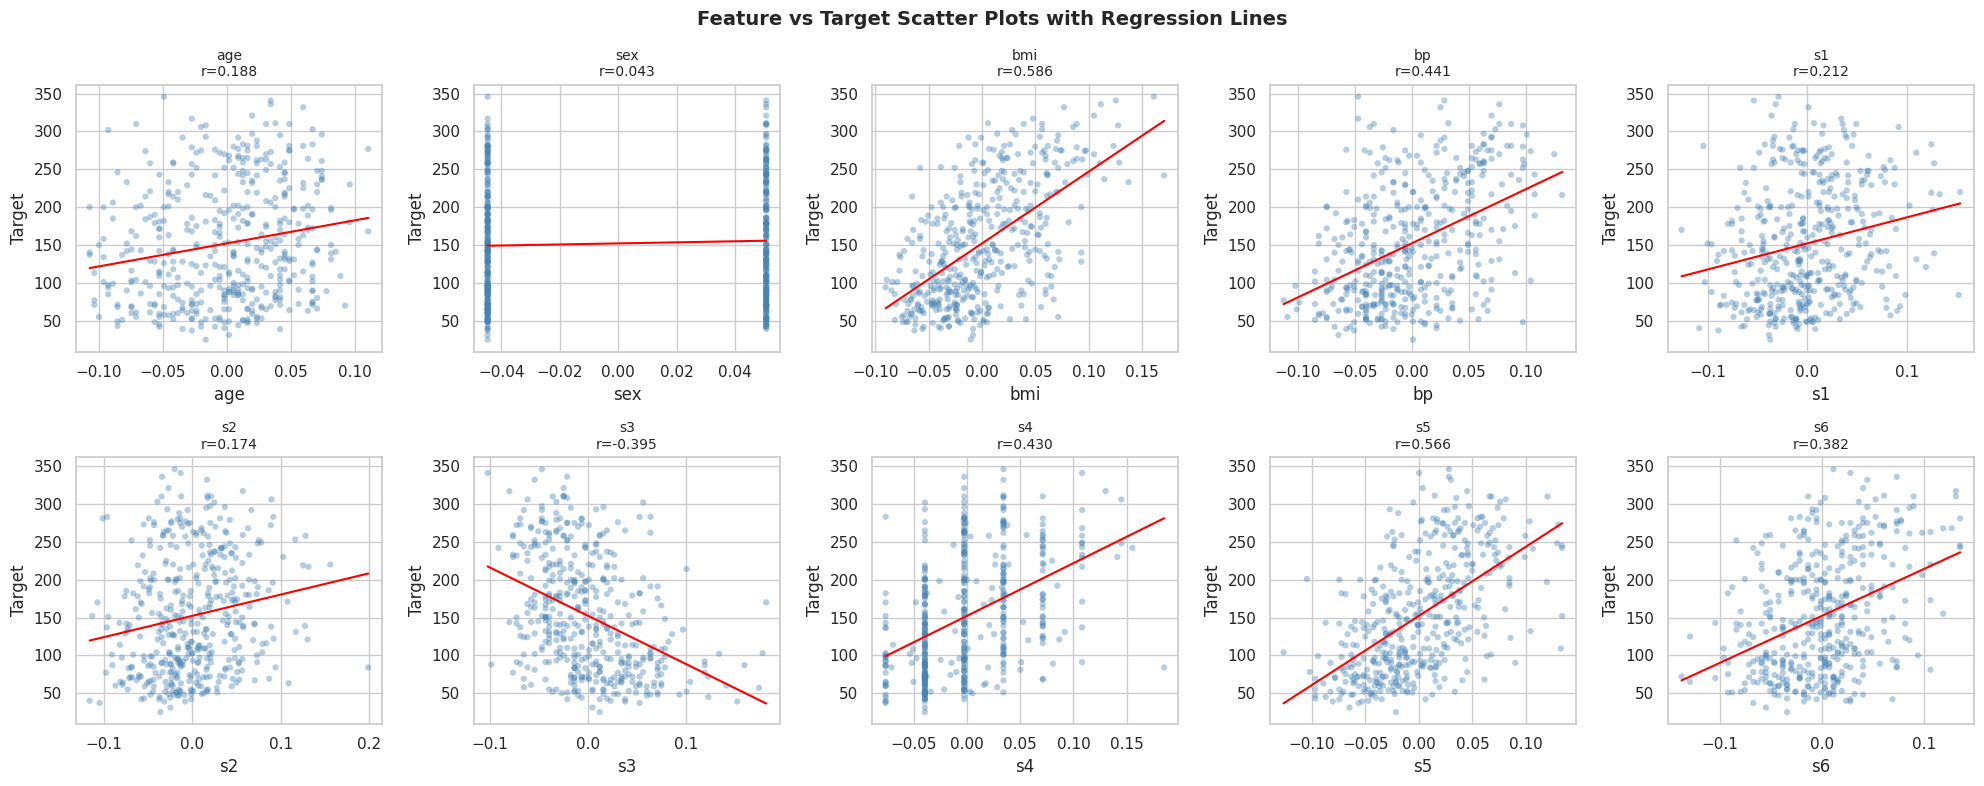

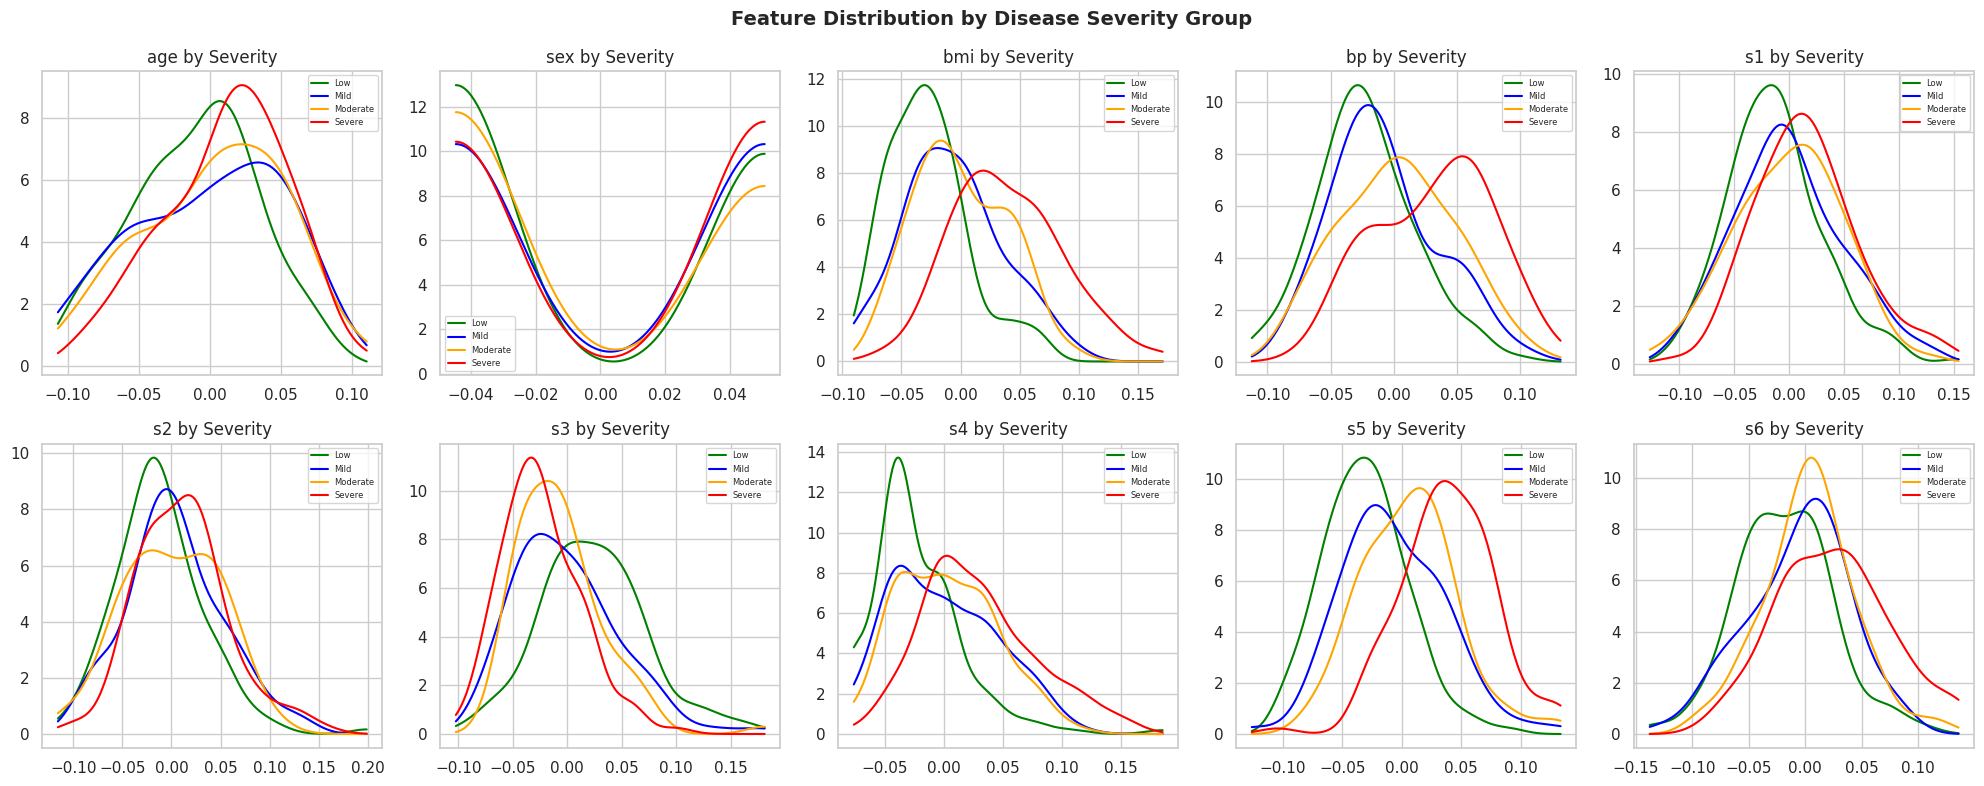

In [41]:
from scipy.stats import gaussian_kde

print("=" * 60)
print("8. FEATURE vs TARGET RELATIONSHIPS")
print("=" * 60)

# 8.1 Scatter plots with regression line
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, feat in enumerate(FEATURES):
    # Scatter
    axes[i].scatter(df[feat], y, alpha=0.4,
                    s=20, color='steelblue', edgecolors='none')
    # Regression line
    m, b, r, p, se = stats.linregress(df[feat], y)
    x_line = np.linspace(df[feat].min(), df[feat].max(), 100)
    axes[i].plot(x_line, m*x_line + b, color='red', lw=1.5)
    # Correlation
    r_val = df[feat].corr(pd.Series(y))
    axes[i].set_title(f'{feat}\nr={r_val:.3f}', fontsize=10)
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('Target')

plt.suptitle('Feature vs Target Scatter Plots with Regression Lines',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 8.2 KDE plots (feature vs target binned)
bins   = [0, 100, 150, 200, 350]
labels = ['Low', 'Mild', 'Moderate', 'Severe']
df['severity'] = pd.cut(y, bins=bins, labels=labels)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, feat in enumerate(FEATURES):
    for sev, color in zip(labels, ['green', 'blue', 'orange', 'red']):
        subset = df[df['severity'] == sev][feat]
        if len(subset) > 1:
            kde = gaussian_kde(subset)
            x_r = np.linspace(df[feat].min(), df[feat].max(), 200)
            axes[i].plot(x_r, kde(x_r), color=color, lw=1.5, label=sev)
    axes[i].set_title(f'{feat} by Severity')
    axes[i].legend(fontsize=6)

plt.suptitle('Feature Distribution by Disease Severity Group',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

df.drop('severity', axis=1, inplace=True)

**9. PAIRPLOT ANALYSIS**

9. PAIRPLOT ANALYSIS


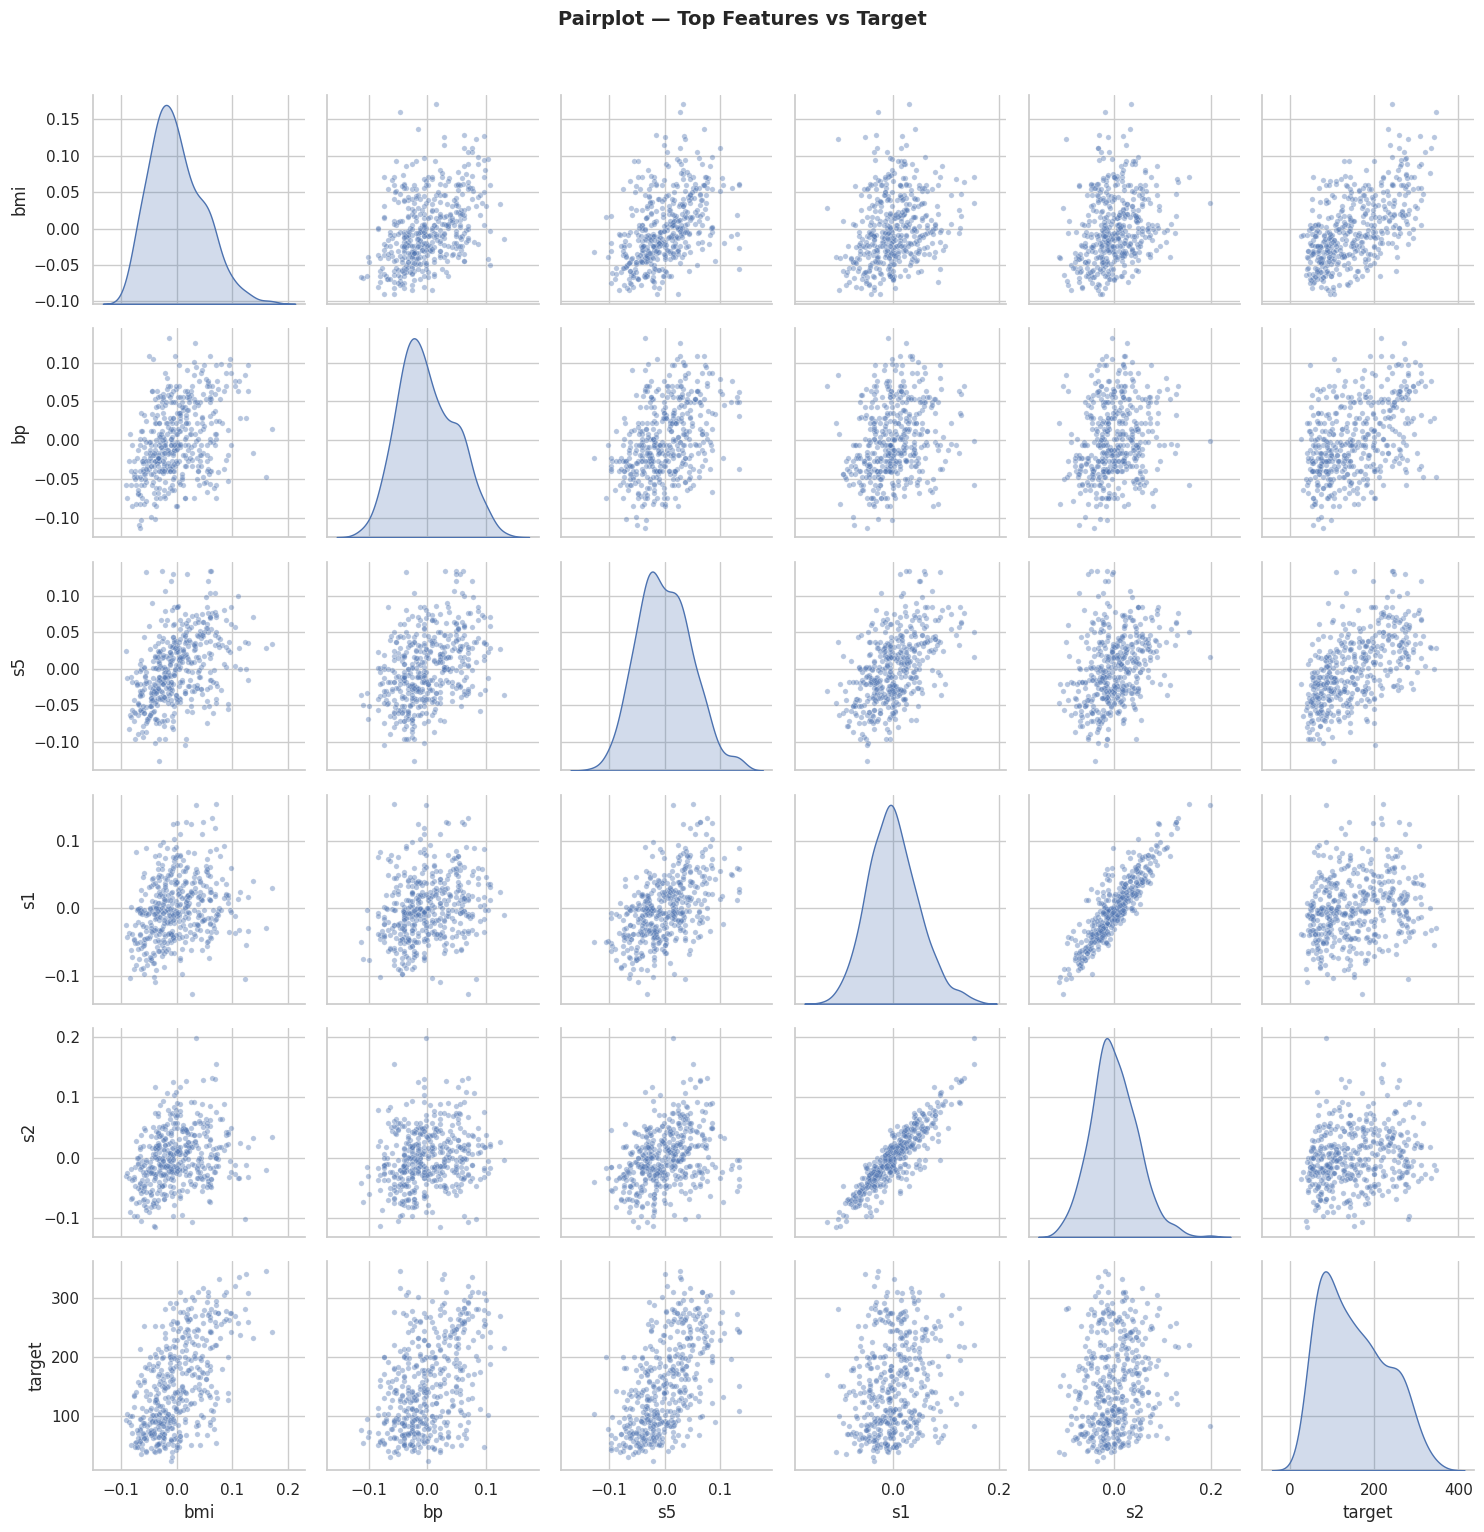

In [42]:
print("=" * 60)
print("9. PAIRPLOT ANALYSIS")
print("=" * 60)

# 9.1 Full pairplot (top features only for readability)
top_features = ['bmi', 'bp', 's5', 's1', 's2', 'target']
pair_df = df[top_features]

g = sns.pairplot(pair_df,
                 diag_kind='kde',
                 plot_kws={'alpha': 0.4, 's': 15},
                 diag_kws={'shade': True},
                 corner=False)
g.fig.suptitle('Pairplot — Top Features vs Target',
               y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**10. FEATURE IMPORTANCE (STATISTICAL)**

10. STATISTICAL FEATURE IMPORTANCE


,Feature,Pearson r,Pearson p-value,Spearman r,Spearman p-value,Pearson |r|,Significant (p<0.05)
2,bmi,0.5865,0.0000,0.5614,0.0000,0.5865,✅
8,s5,0.5659,0.0000,0.5894,0.0000,0.5659,✅
3,bp,0.4415,0.0000,0.4162,0.0000,0.4415,✅
7,s4,0.4305,0.0000,0.4489,0.0000,0.4305,✅
6,s3,-0.3948,0.0000,-0.4100,0.0000,0.3948,✅
9,s6,0.3825,0.0000,0.3508,0.0000,0.3825,✅
4,s1,0.2120,0.0000,0.2324,0.0000,0.2120,✅
0,age,0.1879,0.0001,0.1978,0.0000,0.1879,✅
5,s2,0.1741,0.0002,0.1958,0.0000,0.1741,✅
1,sex,0.0431,0.3664,0.0374,0.4328,0.0431,❌


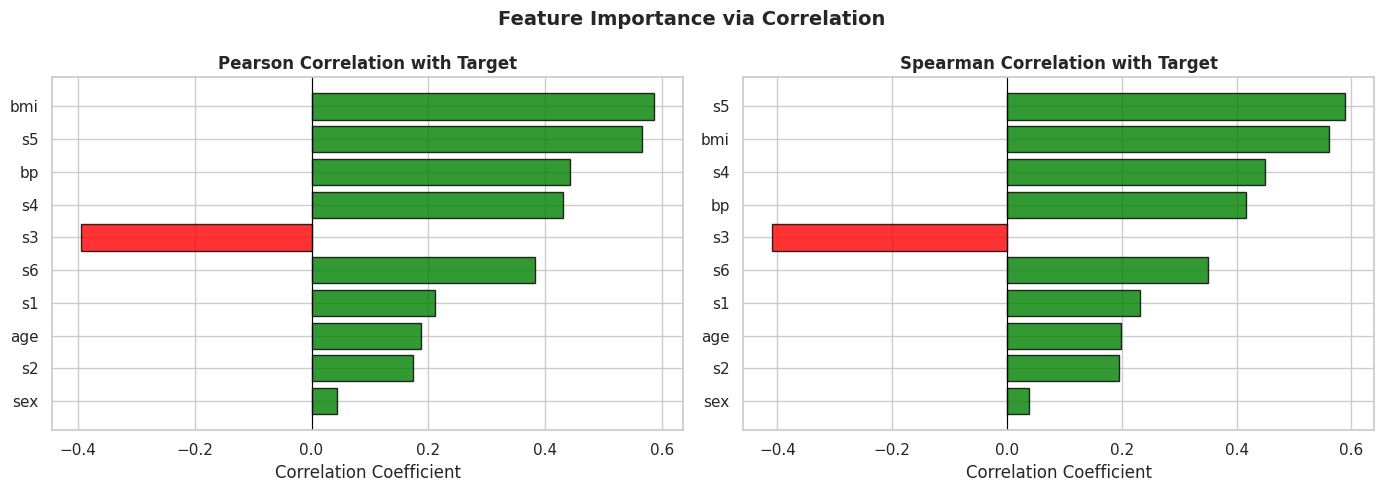

In [43]:
print("=" * 60)
print("10. STATISTICAL FEATURE IMPORTANCE")
print("=" * 60)

importance_results = []

for feat in FEATURES:
    # Pearson correlation
    r_pearson, p_pearson = stats.pearsonr(df[feat], y)
    # Spearman correlation
    r_spearman, p_spearman = stats.spearmanr(df[feat], y)
    # Mutual information proxy (via correlation ratio)
    importance_results.append({
        'Feature':            feat,
        'Pearson r':          round(r_pearson, 4),
        'Pearson p-value':    round(p_pearson, 4),
        'Spearman r':         round(r_spearman, 4),
        'Spearman p-value':   round(p_spearman, 4),
        'Pearson |r|':        round(abs(r_pearson), 4),
        'Significant (p<0.05)': '✅' if p_pearson < 0.05 else '❌'
    })

imp_df = pd.DataFrame(importance_results).sort_values(
    'Pearson |r|', ascending=False)
display(imp_df)

# Visualise
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pearson
imp_df_sorted = imp_df.sort_values('Pearson r', key=abs, ascending=True)
colors = ['green' if v > 0 else 'red' for v in imp_df_sorted['Pearson r']]
axes[0].barh(imp_df_sorted['Feature'],
             imp_df_sorted['Pearson r'],
             color=colors, edgecolor='black', alpha=0.8)
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_title('Pearson Correlation with Target', fontweight='bold')
axes[0].set_xlabel('Correlation Coefficient')

# Spearman
imp_df_sorted2 = imp_df.sort_values('Spearman r', key=abs, ascending=True)
colors2 = ['green' if v > 0 else 'red' for v in imp_df_sorted2['Spearman r']]
axes[1].barh(imp_df_sorted2['Feature'],
             imp_df_sorted2['Spearman r'],
             color=colors2, edgecolor='black', alpha=0.8)
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_title('Spearman Correlation with Target', fontweight='bold')
axes[1].set_xlabel('Correlation Coefficient')

plt.suptitle('Feature Importance via Correlation',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**11. MULTICOLLINEARITY — VIF**

11. MULTICOLLINEARITY — VARIANCE INFLATION FACTOR (VIF)


,Feature,VIF,R²,Multicollinearity
4,s1,59.20,0.9831,🔴 High
5,s2,39.19,0.9745,🔴 High
6,s3,15.40,0.9351,🔴 High
8,s5,10.08,0.9008,🔴 High
7,s4,8.89,0.8875,🟡 Moderate
2,bmi,1.51,0.3375,🟢 Low
9,s6,1.48,0.3264,🟢 Low
3,bp,1.46,0.3148,🟢 Low
1,sex,1.28,0.2176,🟢 Low
0,age,1.22,0.1785,🟢 Low


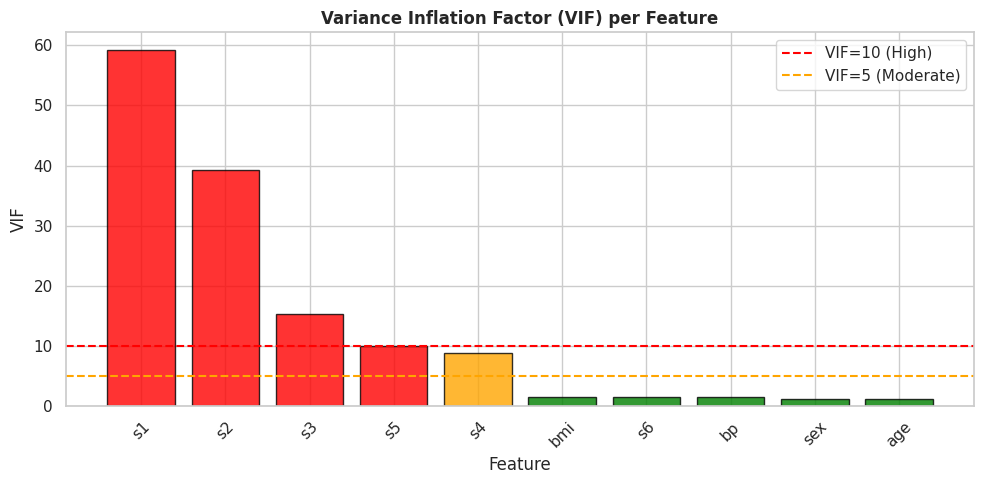

In [44]:
print("=" * 60)
print("11. MULTICOLLINEARITY — VARIANCE INFLATION FACTOR (VIF)")
print("=" * 60)

from sklearn.linear_model import LinearRegression

# Extract the feature matrix from df
X_matrix = df[FEATURES].values

vif_results = []
for i, feat in enumerate(FEATURES):
    # Regress feature i on all others
    X_others = np.delete(X_matrix, i, axis=1)
    r2 = LinearRegression().fit(X_others, X_matrix[:, i]).score(X_others, X_matrix[:, i])
    vif = 1 / (1 - r2) if r2 < 1 else np.inf
    vif_results.append({
        'Feature': feat,
        'VIF': round(vif, 2),
        'R²': round(r2, 4),
        'Multicollinearity': '🔴 High' if vif > 10 else
                             '🟡 Moderate' if vif > 5 else
                             '🟢 Low'
    })

vif_df = pd.DataFrame(vif_results).sort_values('VIF', ascending=False)
display(vif_df)

# VIF bar chart
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['red' if v > 10 else 'orange' if v > 5 else 'green'
          for v in vif_df['VIF']]
ax.bar(vif_df['Feature'], vif_df['VIF'],
       color=colors, edgecolor='black', alpha=0.8)
ax.axhline(10, color='red', ls='--', lw=1.5, label='VIF=10 (High)')
ax.axhline(5, color='orange', ls='--', lw=1.5, label='VIF=5 (Moderate)')
ax.set_title('Variance Inflation Factor (VIF) per Feature',
             fontweight='bold')
ax.set_xlabel('Feature')
ax.set_ylabel('VIF')
ax.legend()
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**12. PRINCIPAL COMPONENT ANALYSIS (PCA)**

12. PCA — DIMENSIONALITY ANALYSIS


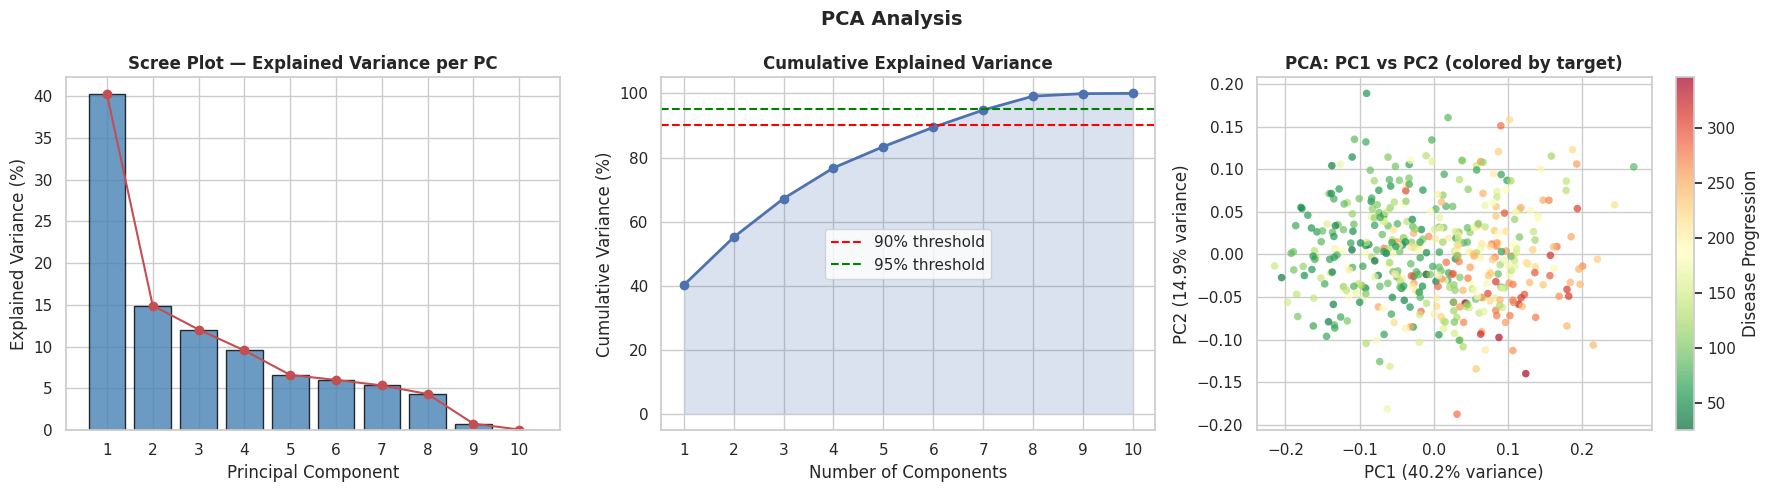


📌 Components needed for 90% variance: 7
📌 Components needed for 95% variance: 8

📌 PCA Loadings (contribution of each feature to each PC):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
age,0.216,0.044,0.495,0.414,0.687,-0.226,-0.110,-0.015,0.008,0.003
sex,0.187,-0.387,-0.107,0.680,-0.373,0.042,-0.068,-0.443,-0.002,0.004
bmi,0.303,-0.156,0.168,-0.500,-0.129,-0.403,-0.520,-0.393,0.042,0.008
bp,0.272,-0.138,0.514,0.020,-0.487,-0.273,0.321,0.477,0.027,-0.003
s1,0.343,0.573,-0.069,0.068,-0.129,0.005,0.074,-0.129,-0.042,0.710
s2,0.352,0.456,-0.270,0.168,-0.117,-0.133,-0.231,0.191,-0.359,-0.563
s3,-0.282,0.506,0.386,0.076,-0.245,0.106,-0.008,-0.325,0.481,-0.317
s4,0.429,-0.068,-0.381,-0.008,0.144,-0.034,0.071,0.181,0.774,-0.091
s5,0.379,-0.026,0.064,-0.264,0.152,0.179,0.647,-0.450,-0.189,-0.264
s6,0.322,-0.085,0.277,-0.087,-0.031,0.805,-0.357,0.167,-0.015,0.003


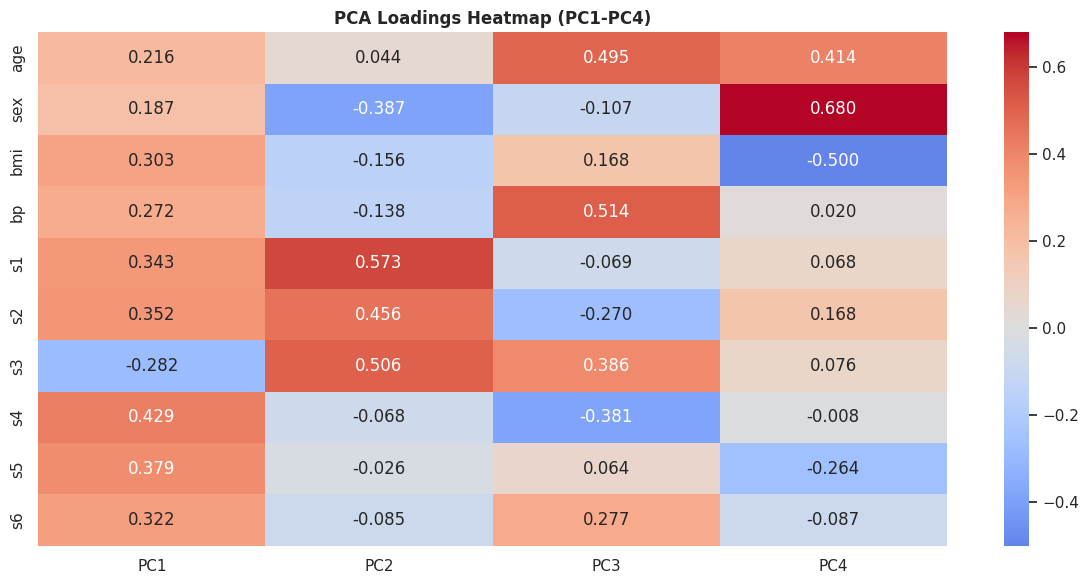

In [45]:
print("=" * 60)
print("12. PCA — DIMENSIONALITY ANALYSIS")
print("=" * 60)

from sklearn.decomposition import PCA

pca   = PCA()
# Use df[FEATURES] as X is not defined globally
X_pca = pca.fit_transform(df[FEATURES])

# Explained variance
exp_var     = pca.explained_variance_ratio_
cum_exp_var = np.cumsum(exp_var)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 12.1 Scree plot
axes[0].bar(range(1, 11), exp_var * 100,
            color='steelblue', edgecolor='black', alpha=0.8)
axes[0].plot(range(1, 11), exp_var * 100,
             'ro-', lw=1.5, markersize=6)
axes[0].set_title('Scree Plot — Explained Variance per PC',
                  fontweight='bold')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_xticks(range(1, 11))

# 12.2 Cumulative explained variance
axes[1].plot(range(1, 11), cum_exp_var * 100, 'bo-', lw=2)
axes[1].axhline(90, color='red', ls='--', label='90% threshold')
axes[1].axhline(95, color='green', ls='--', label='95% threshold')
axes[1].fill_between(range(1, 11), cum_exp_var * 100, alpha=0.2)
axes[1].set_title('Cumulative Explained Variance', fontweight='bold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].set_xticks(range(1, 11))
axes[1].legend()

# 12.3 PC1 vs PC2 colored by target
scatter = axes[2].scatter(X_pca[:, 0], X_pca[:, 1],
                           c=y, cmap='RdYlGn_r',
                           alpha=0.7, s=30, edgecolors='none')
plt.colorbar(scatter, ax=axes[2], label='Disease Progression')
axes[2].set_title('PCA: PC1 vs PC2 (colored by target)',
                  fontweight='bold')
axes[2].set_xlabel(f'PC1 ({exp_var[0]*100:.1f}% variance)')
axes[2].set_ylabel(f'PC2 ({exp_var[1]*100:.1f}% variance)')

plt.suptitle('PCA Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n📌 Components needed for 90% variance: "
      f"{np.argmax(cum_exp_var >= 0.90) + 1}")
print(f"📌 Components needed for 95% variance: "
      f"{np.argmax(cum_exp_var >= 0.95) + 1}")

# PCA loadings - replaced feat_names with FEATURES
loadings_df = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(10)],
    index=FEATURES
)
print("\n📌 PCA Loadings (contribution of each feature to each PC):")
display(loadings_df.round(3))

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(loadings_df[['PC1','PC2','PC3','PC4']],
            annot=True, fmt='.3f',
            cmap='coolwarm', center=0, ax=ax)
ax.set_title('PCA Loadings Heatmap (PC1-PC4)', fontweight='bold')
plt.tight_layout()
plt.show()

**13. COMPLETE EDA SUMMARY**

In [46]:
print("=" * 60)
print("13. EDA SUMMARY REPORT")
print("=" * 60)

from scipy.stats import skew

summary = {
    'Total Samples':          len(df),
    'Total Features':         len(FEATURES),
    'Missing Values':         df.isnull().sum().sum(),
    'Target Mean':            round(y.mean(), 2),
    'Target Median':          round(np.median(y), 2),
    'Target Std':             round(y.std(), 2),
    'Target Min':             round(y.min(), 2),
    'Target Max':             round(y.max(), 2),
    'Target Skewness':        round(skew(y), 4),
    'Best Predictor':         target_corr.index[0],
    'Best Predictor Corr':    round(target_corr.iloc[0], 4),
    'High Multicollinearity': f"s1↔s2 (r={corr.loc['s1','s2']:.2f})",
    'PCA 90% components':     int(np.argmax(cum_exp_var >= 0.90) + 1),
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=['Metric', 'Value']
)
display(summary_df)

print("""
ထ KEY EDA FINDINGS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
1. No missing values — clean dataset
2. Target is approximately normal (slight right skew)
3. BMI and S5 are strongest predictors (r > 0.55)
4. High multicollinearity: S1↔S2 (r=0.90), S1↔S3 (r=-0.81)
5. Age and Sex are weak predictors (r < 0.2)
6. 7 PCA components capture 90% of variance
7. All features already standardized (mean≈0, std≈1)
8. Outliers present in S1, S2, S6 — but manageable
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
""")

13. EDA SUMMARY REPORT


,Metric,Value
0,Total Samples,442
1,Total Features,10
2,Missing Values,0
3,Target Mean,152.13
4,Target Median,140.5
5,Target Std,77.09
6,Target Min,25.0
7,Target Max,346.0
8,Target Skewness,0.4391
9,Best Predictor,bmi



ထ KEY EDA FINDINGS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
1. No missing values — clean dataset
2. Target is approximately normal (slight right skew)
3. BMI and S5 are strongest predictors (r > 0.55)
4. High multicollinearity: S1↔S2 (r=0.90), S1↔S3 (r=-0.81)
5. Age and Sex are weak predictors (r < 0.2)
6. 7 PCA components capture 90% of variance
7. All features already standardized (mean≈0, std≈1)
8. Outliers present in S1, S2, S6 — but manageable
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━



**TRAIN/TEST SPLIT**

In [47]:
from sklearn.model_selection import train_test_split

# Define X and y first
X = df[FEATURES]
y = df['target']

# Split ONCE — test set locked away until final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(f" Train set: {X_train.shape[0]} samples")
print(f" Test  set: {X_test.shape[0]} samples")
print(f" Features : {X_train.shape[1]}")
print(f"\n Train target — Mean: {y_train.mean():.2f}, Std: {y_train.std():.2f}")
print(f" Test  target — Mean: {y_test.mean():.2f},  Std: {y_test.std():.2f}")

 Train set: 353 samples
 Test  set: 89 samples
 Features : 10

 Train target — Mean: 153.74, Std: 78.06
 Test  target — Mean: 145.78,  Std: 73.20


**EVALUATION FUNCTION**

In [48]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    """
    Returns full evaluation metrics for train and test sets.
    """
    y_pred_train = model.predict(X_tr)
    y_pred_test  = model.predict(X_te)

    metrics = {
        'Model':        name,
        'Train R²':     round(r2_score(y_tr, y_pred_train), 4),
        'Test R²':      round(r2_score(y_te, y_pred_test),  4),
        'Train RMSE':   round(np.sqrt(mean_squared_error(y_tr, y_pred_train)), 4),
        'Test RMSE':    round(np.sqrt(mean_squared_error(y_te, y_pred_test)),  4),
        'Train MAE':    round(mean_absolute_error(y_tr, y_pred_train), 4),
        'Test MAE':     round(mean_absolute_error(y_te, y_pred_test),  4),
    }
    return metrics, y_pred_test

all_results = []   # collect all model results here

**MODEL 1: OLS LINEAR REGRESSION (Baseline)**

MODEL 1 — OLS Linear Regression (Baseline)

 Intercept: 151.3456

 Coefficients:


,Feature,Coefficient
4,s1,-931.4888
8,s5,736.1989
2,bmi,542.4288
5,s2,518.0623
3,bp,347.7038
7,s4,275.3179
1,sex,-241.9644
6,s3,163.4200
9,s6,48.6707
0,age,37.9040



 Train R²: 0.5279
 Test  R²: 0.4526
 Test RMSE: 53.8534
 Test MAE:  42.7941


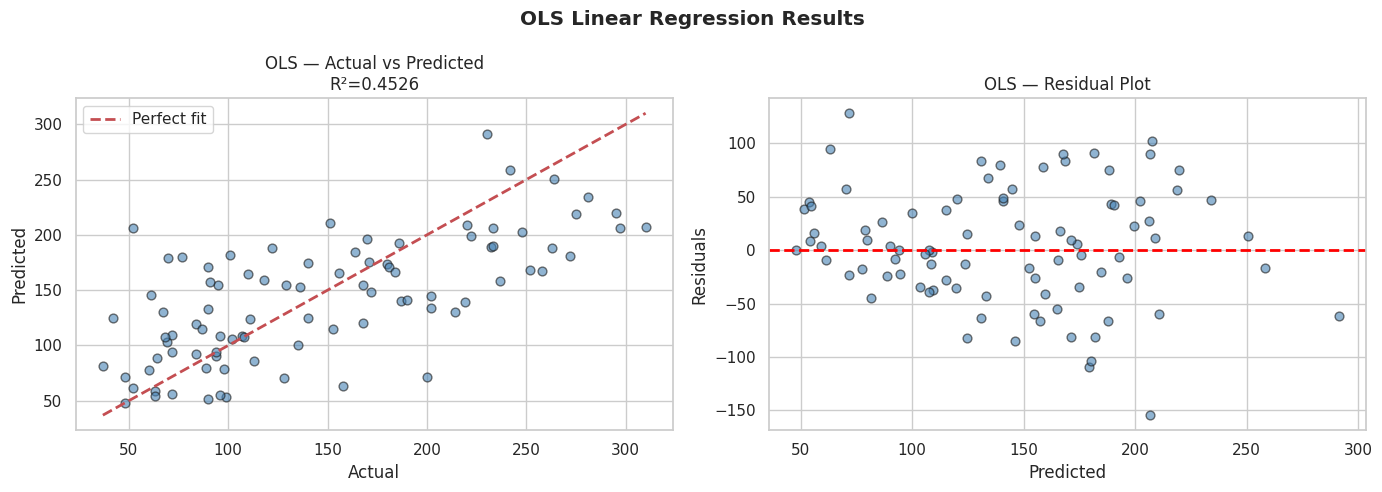

In [49]:
from sklearn.linear_model import LinearRegression

print("=" * 60)
print("MODEL 1 — OLS Linear Regression (Baseline)")
print("=" * 60)

ols = LinearRegression()
ols.fit(X_train, y_train)

metrics_ols, y_pred_ols = evaluate_model(
    "OLS (Raw)", ols, X_train, y_train, X_test, y_test
)
all_results.append(metrics_ols)

# Coefficients
coef_ols = pd.DataFrame({
    'Feature':     FEATURES,
    'Coefficient': np.round(ols.coef_, 4)
}).sort_values('Coefficient', key=abs, ascending=False)

print(f"\n Intercept: {ols.intercept_:.4f}")
print("\n Coefficients:")
display(coef_ols)

print(f"\n Train R²: {metrics_ols['Train R²']}")
print(f" Test  R²: {metrics_ols['Test R²']}")
print(f" Test RMSE: {metrics_ols['Test RMSE']}")
print(f" Test MAE:  {metrics_ols['Test MAE']}")

# Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_ols, alpha=0.6,
                color='steelblue', edgecolors='k', s=40)
axes[0].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()],
             'r--', lw=2, label='Perfect fit')
axes[0].set_title(f'OLS — Actual vs Predicted\nR²={metrics_ols["Test R²"]}')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].legend()

residuals = y_test - y_pred_ols
axes[1].scatter(y_pred_ols, residuals, alpha=0.6,
                color='steelblue', edgecolors='k', s=40)
axes[1].axhline(0, color='red', ls='--', lw=2)
axes[1].set_title('OLS — Residual Plot')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Residuals')

plt.suptitle('OLS Linear Regression Results', fontweight='bold')
plt.tight_layout()
plt.show()

**MODEL 2: RIDGE REGRESSION**

MODEL 2 — Ridge Regression
 Best alpha (λ): 0.1

 OLS vs Ridge Coefficients:


,Feature,OLS Coef,Ridge Coef,Shrinkage
4,s1,-931.4888,-108.5003,-822.9886
8,s5,736.1989,392.2893,343.9095
2,bmi,542.4288,505.0890,37.3397
5,s2,518.0623,-86.2367,604.2990
3,bp,347.7038,317.0932,30.6106
7,s4,275.3179,151.7071,123.6108
1,sex,-241.9644,-205.4943,-36.4700
6,s3,163.4200,-190.3632,353.7832
9,s6,48.6707,79.9082,-31.2375
0,age,37.9040,42.8557,-4.9516



 Train R²:  0.5206
 Test  R²:  0.4609
 Test RMSE: 53.4461


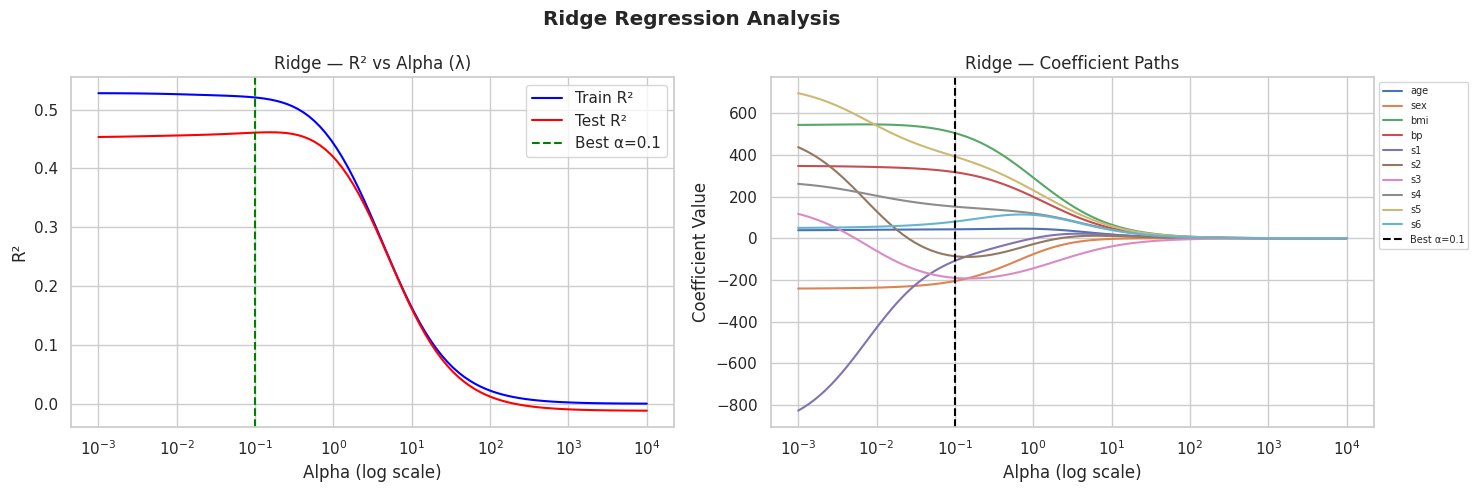

In [50]:
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import cross_val_score

print("=" * 60)
print("MODEL 2 — Ridge Regression")
print("=" * 60)

# Hyperparameter tuning via cross-validation on TRAIN only
alphas = [0.001, 0.01, 0.1, 1, 10, 50, 100, 500, 1000]

ridge_cv = RidgeCV(alphas=alphas, cv=10, scoring='r2')
ridge_cv.fit(X_train, y_train)

print(f" Best alpha (λ): {ridge_cv.alpha_}")

# Final model with best alpha
ridge = Ridge(alpha=ridge_cv.alpha_)
ridge.fit(X_train, y_train)

metrics_ridge, y_pred_ridge = evaluate_model(
    "Ridge (Raw)", ridge, X_train, y_train, X_test, y_test
)
all_results.append(metrics_ridge)

# Coefficients
coef_ridge = pd.DataFrame({
    'Feature':     FEATURES,
    'OLS Coef':    np.round(ols.coef_, 4),
    'Ridge Coef':  np.round(ridge.coef_, 4),
    'Shrinkage':   np.round(ols.coef_ - ridge.coef_, 4)
}).sort_values('OLS Coef', key=abs, ascending=False)

print("\n OLS vs Ridge Coefficients:")
display(coef_ridge)

print(f"\n Train R²:  {metrics_ridge['Train R²']}")
print(f" Test  R²:  {metrics_ridge['Test R²']}")
print(f" Test RMSE: {metrics_ridge['Test RMSE']}")

# Alpha sensitivity — how does R² change with alpha?
alpha_range = np.logspace(-3, 4, 100)
ridge_train_r2, ridge_test_r2 = [], []

for a in alpha_range:
    r = Ridge(alpha=a).fit(X_train, y_train)
    ridge_train_r2.append(r2_score(y_train, r.predict(X_train)))
    ridge_test_r2.append(r2_score(y_test,  r.predict(X_test)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogx(alpha_range, ridge_train_r2, label='Train R²', color='blue')
axes[0].semilogx(alpha_range, ridge_test_r2,  label='Test R²',  color='red')
axes[0].axvline(ridge_cv.alpha_, color='green', ls='--',
                label=f'Best α={ridge_cv.alpha_}')
axes[0].set_title('Ridge — R² vs Alpha (λ)')
axes[0].set_xlabel('Alpha (log scale)')
axes[0].set_ylabel('R²')
axes[0].legend()

# Coefficient paths
coef_paths = []
for a in alpha_range:
    coef_paths.append(Ridge(alpha=a).fit(X_train, y_train).coef_)
coef_paths = np.array(coef_paths)

for i, feat in enumerate(FEATURES):
    axes[1].semilogx(alpha_range, coef_paths[:, i], label=feat)
axes[1].axvline(ridge_cv.alpha_, color='black', ls='--', lw=1.5,
                label=f'Best α={ridge_cv.alpha_}')
axes[1].set_title('Ridge — Coefficient Paths')
axes[1].set_xlabel('Alpha (log scale)')
axes[1].set_ylabel('Coefficient Value')
axes[1].legend(fontsize=7, bbox_to_anchor=(1, 1))

plt.suptitle('Ridge Regression Analysis', fontweight='bold')
plt.tight_layout()
plt.show()

**MODEL 3: LASSO REGRESSION**

MODEL 3 — Lasso Regression
 Best alpha (λ): 0.006579

 All Three Models — Coefficient Comparison:


,Feature,OLS Coef,Ridge Coef,Lasso Coef,Selected
8,s5,736.1989,392.2893,602.4961,✅
4,s1,-931.4888,-108.5003,-571.5990,✅
2,bmi,542.4288,505.0890,548.4894,✅
3,bp,347.7038,317.0932,343.0519,✅
5,s2,518.0623,-86.2367,241.1849,✅
1,sex,-241.9644,-205.4943,-235.7770,✅
7,s4,275.3179,151.7071,216.1535,✅
9,s6,48.6707,79.9082,49.6201,✅
0,age,37.9040,42.8557,36.6190,✅
6,s3,163.4200,-190.3632,-0.0000,❌



 Lasso selected 9/10 features
 Zeroed out features: ['s3']


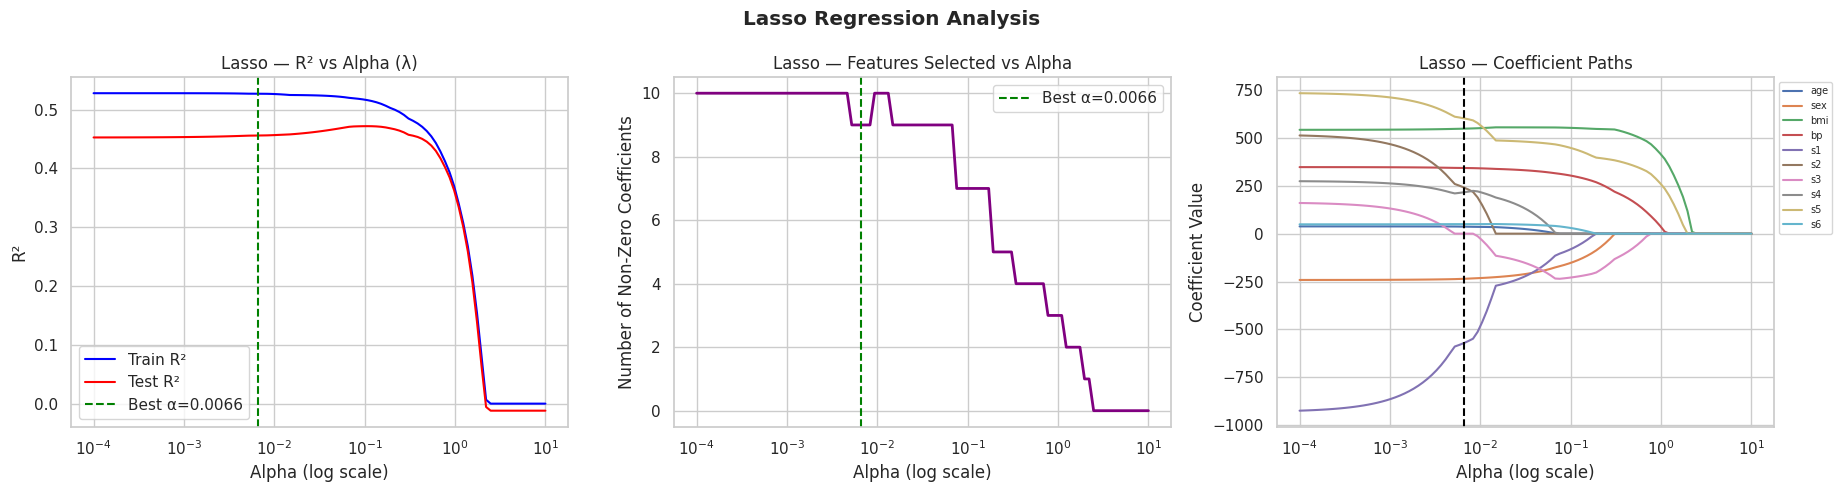

In [51]:
from sklearn.linear_model import Lasso, LassoCV

print("=" * 60)
print("MODEL 3 — Lasso Regression")
print("=" * 60)

# Hyperparameter tuning via cross-validation on TRAIN only
lasso_cv = LassoCV(
    alphas=np.logspace(-4, 1, 100),
    cv=10,
    max_iter=10000,
    random_state=42
)
lasso_cv.fit(X_train, y_train)

print(f" Best alpha (λ): {lasso_cv.alpha_:.6f}")

lasso = Lasso(alpha=lasso_cv.alpha_, max_iter=10000)
lasso.fit(X_train, y_train)

metrics_lasso, y_pred_lasso = evaluate_model(
    "Lasso (Raw)", lasso, X_train, y_train, X_test, y_test
)
all_results.append(metrics_lasso)

# Which features survived?
coef_lasso = pd.DataFrame({
    'Feature':       FEATURES,
    'OLS Coef':      np.round(ols.coef_, 4),
    'Ridge Coef':    np.round(ridge.coef_, 4),
    'Lasso Coef':    np.round(lasso.coef_, 4),
    'Selected':      ['✅' if c != 0 else '❌' for c in lasso.coef_]
}).sort_values('Lasso Coef', key=abs, ascending=False)

print("\n All Three Models — Coefficient Comparison:")
display(coef_lasso)

n_selected = np.sum(lasso.coef_ != 0)
print(f"\n Lasso selected {n_selected}/{len(FEATURES)} features")
print(f" Zeroed out features: "
      f"{[f for f, c in zip(FEATURES, lasso.coef_) if c == 0]}")

# Alpha sensitivity — Lasso
alpha_range_l = np.logspace(-4, 1, 100)
lasso_train_r2, lasso_test_r2, lasso_nonzero = [], [], []

for a in alpha_range_l:
    l = Lasso(alpha=a, max_iter=10000).fit(X_train, y_train)
    lasso_train_r2.append(r2_score(y_train, l.predict(X_train)))
    lasso_test_r2.append(r2_score(y_test,  l.predict(X_test)))
    lasso_nonzero.append(np.sum(l.coef_ != 0))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# R² vs alpha
axes[0].semilogx(alpha_range_l, lasso_train_r2, label='Train R²', color='blue')
axes[0].semilogx(alpha_range_l, lasso_test_r2,  label='Test R²',  color='red')
axes[0].axvline(lasso_cv.alpha_, color='green', ls='--',
                label=f'Best α={lasso_cv.alpha_:.4f}')
axes[0].set_title('Lasso — R² vs Alpha (λ)')
axes[0].set_xlabel('Alpha (log scale)')
axes[0].set_ylabel('R²')
axes[0].legend()

# Non-zero coefficients vs alpha
axes[1].semilogx(alpha_range_l, lasso_nonzero, color='purple', lw=2)
axes[1].axvline(lasso_cv.alpha_, color='green', ls='--',
                label=f'Best α={lasso_cv.alpha_:.4f}')
axes[1].set_title('Lasso — Features Selected vs Alpha')
axes[1].set_xlabel('Alpha (log scale)')
axes[1].set_ylabel('Number of Non-Zero Coefficients')
axes[1].legend()

# Coefficient paths
lasso_coef_paths = []
for a in alpha_range_l:
    lasso_coef_paths.append(
        Lasso(alpha=a, max_iter=10000).fit(X_train, y_train).coef_
    )
lasso_coef_paths = np.array(lasso_coef_paths)

for i, feat in enumerate(FEATURES):
    axes[2].semilogx(alpha_range_l, lasso_coef_paths[:, i], label=feat)
axes[2].axvline(lasso_cv.alpha_, color='black', ls='--', lw=1.5)
axes[2].set_title('Lasso — Coefficient Paths')
axes[2].set_xlabel('Alpha (log scale)')
axes[2].set_ylabel('Coefficient Value')
axes[2].legend(fontsize=7, bbox_to_anchor=(1, 1))

plt.suptitle('Lasso Regression Analysis', fontweight='bold')
plt.tight_layout()
plt.show()

**FEATURE ENGINEERING**

In [52]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

print("=" * 60)
print("STEP 6 — FEATURE ENGINEERING")
print("=" * 60)

# Degree 1 = raw (10 features)
# Degree 2 = powers + interactions (65 features)
# Degree 3 = higher powers + interactions (285 features)

for degree in [2, 3]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly  = poly.transform(X_test)
    n_feat       = X_train_poly.shape[1]

    print(f"\n{'─'*50}")
    print(f"Polynomial Degree {degree} → {n_feat} features")
    print(f"{'─'*50}")

    # ── OLS ────────────────────────────────────────────
    ols_p = LinearRegression()
    ols_p.fit(X_train_poly, y_train)
    m, y_p = evaluate_model(
        f"OLS (Poly{degree})",
        ols_p, X_train_poly, y_train, X_test_poly, y_test
    )
    all_results.append(m)
    print(f"OLS  (Poly{degree}) → Train R²: {m['Train R²']:.4f} | "
          f"Test R²: {m['Test R²']:.4f}")

    # ── Ridge ──────────────────────────────────────────
    ridge_p_cv = RidgeCV(alphas=alphas, cv=10, scoring='r2')
    ridge_p_cv.fit(X_train_poly, y_train)
    ridge_p = Ridge(alpha=ridge_p_cv.alpha_)
    ridge_p.fit(X_train_poly, y_train)
    m, y_p = evaluate_model(
        f"Ridge (Poly{degree})",
        ridge_p, X_train_poly, y_train, X_test_poly, y_test
    )
    all_results.append(m)
    print(f"Ridge(Poly{degree}) → Train R²: {m['Train R²']:.4f} | "
          f"Test R²: {m['Test R²']:.4f} | α={ridge_p_cv.alpha_}")

    # ── Lasso ──────────────────────────────────────────
    lasso_p_cv = LassoCV(
        alphas=np.logspace(-4, 1, 100),
        cv=10, max_iter=10000, random_state=42
    )
    lasso_p_cv.fit(X_train_poly, y_train)
    lasso_p = Lasso(alpha=lasso_p_cv.alpha_, max_iter=10000)
    lasso_p.fit(X_train_poly, y_train)
    n_sel = np.sum(lasso_p.coef_ != 0)
    m, y_p = evaluate_model(
        f"Lasso (Poly{degree})",
        lasso_p, X_train_poly, y_train, X_test_poly, y_test
    )
    all_results.append(m)
    print(f"Lasso(Poly{degree}) → Train R²: {m['Train R²']:.4f} | "
          f"Test R²: {m['Test R²']:.4f} | "
          f"α={lasso_p_cv.alpha_:.4f} | "
          f"Features selected: {n_sel}/{n_feat}")

STEP 6 — FEATURE ENGINEERING

──────────────────────────────────────────────────
Polynomial Degree 2 → 65 features
──────────────────────────────────────────────────
OLS  (Poly2) → Train R²: 0.6062 | Test R²: 0.4156
Ridge(Poly2) → Train R²: 0.5238 | Test R²: 0.4659 | α=0.1
Lasso(Poly2) → Train R²: 0.5200 | Test R²: 0.4708 | α=0.0673 | Features selected: 9/65

──────────────────────────────────────────────────
Polynomial Degree 3 → 285 features
──────────────────────────────────────────────────
OLS  (Poly3) → Train R²: 0.8773 | Test R²: -14.5613
Ridge(Poly3) → Train R²: 0.5239 | Test R²: 0.4659 | α=0.1
Lasso(Poly3) → Train R²: 0.5200 | Test R²: 0.4708 | α=0.0673 | Features selected: 9/285


**CROSS-VALIDATION COMPARISON**

STEP 7 — 10-FOLD CROSS-VALIDATION (ON TRAIN ONLY)

 10-Fold Cross-Validation Results (Train set only):


,Model,CV R² Mean,CV R² Std,CV RMSE Mean,CV RMSE Std
1,Ridge (Raw),0.4041,0.2499,55.6204,4.8088
8,Lasso (Poly3),0.4018,0.2529,55.6949,4.8857
5,Lasso (Poly2),0.4018,0.2529,55.6949,4.8857
2,Lasso (Raw),0.3975,0.2746,55.5898,4.8036
0,OLS (Raw),0.3932,0.2883,55.6331,4.9530
3,OLS (Poly2),0.2359,0.4065,62.3521,7.5837
4,Ridge (Poly2),0.0822,0.1253,71.7098,9.1679
7,Ridge (Poly3),-0.0498,0.1265,76.8244,10.1904
6,OLS (Poly3),-141.7247,239.4634,647.5829,423.2072


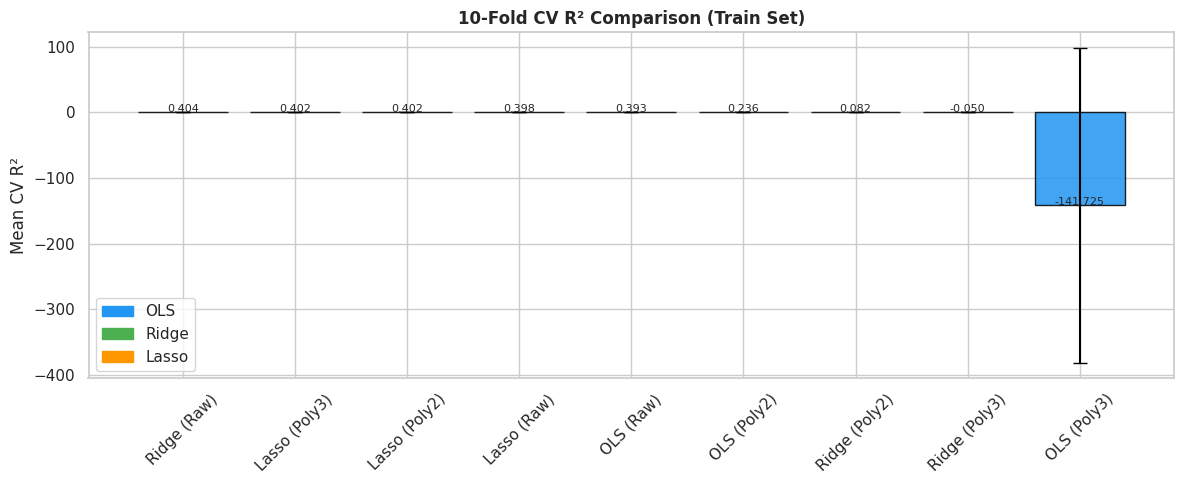

In [53]:
print("=" * 60)
print("STEP 7 — 10-FOLD CROSS-VALIDATION (ON TRAIN ONLY)")
print("=" * 60)

models_for_cv = {
    'OLS (Raw)': Pipeline([
        ('model', LinearRegression())
    ]),
    'Ridge (Raw)': Pipeline([
        ('model', Ridge(alpha=ridge_cv.alpha_))
    ]),
    'Lasso (Raw)': Pipeline([
        ('model', Lasso(alpha=lasso_cv.alpha_, max_iter=10000))
    ]),
    'OLS (Poly2)': Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('model', LinearRegression())
    ]),
    'Ridge (Poly2)': Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('model', Ridge(alpha=10))
    ]),
    'Lasso (Poly2)': Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('model', Lasso(alpha=0.1, max_iter=10000))
    ]),
    'OLS (Poly3)': Pipeline([
        ('poly', PolynomialFeatures(degree=3, include_bias=False)),
        ('model', LinearRegression())
    ]),
    'Ridge (Poly3)': Pipeline([
        ('poly', PolynomialFeatures(degree=3, include_bias=False)),
        ('model', Ridge(alpha=100))
    ]),
    'Lasso (Poly3)': Pipeline([
        ('poly', PolynomialFeatures(degree=3, include_bias=False)),
        ('model', Lasso(alpha=0.1, max_iter=10000))
    ]),
}

cv_summary = []
for name, pipe in models_for_cv.items():
    cv_scores = cross_val_score(
        pipe, X_train, y_train, cv=10, scoring='r2'
    )
    cv_rmse = cross_val_score(
        pipe, X_train, y_train, cv=10,
        scoring='neg_root_mean_squared_error'
    )
    cv_summary.append({
        'Model':        name,
        'CV R² Mean':   round(cv_scores.mean(), 4),
        'CV R² Std':    round(cv_scores.std(), 4),
        'CV RMSE Mean': round(-cv_rmse.mean(), 4),
        'CV RMSE Std':  round(cv_rmse.std(), 4),
    })

cv_df = pd.DataFrame(cv_summary).sort_values('CV R² Mean', ascending=False)
print("\n 10-Fold Cross-Validation Results (Train set only):")
display(cv_df)

# Plot CV R²
fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#2196F3' if 'OLS' in n else
          '#4CAF50' if 'Ridge' in n else
          '#FF9800' for n in cv_df['Model']]
bars = ax.bar(cv_df['Model'], cv_df['CV R² Mean'],
              color=colors, edgecolor='black', alpha=0.85)
ax.errorbar(range(len(cv_df)),
            cv_df['CV R² Mean'],
            yerr=cv_df['CV R² Std'],
            fmt='none', color='black', capsize=5, lw=1.5)
ax.set_title('10-Fold CV R² Comparison (Train Set)',
             fontweight='bold')
ax.set_ylabel('Mean CV R²')
ax.tick_params(axis='x', rotation=45)
for bar, val in zip(bars, cv_df['CV R² Mean']):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.005,
            f'{val:.3f}', ha='center', fontsize=8)
# Legend
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='#2196F3', label='OLS'),
    Patch(color='#4CAF50', label='Ridge'),
    Patch(color='#FF9800', label='Lasso')
])
plt.tight_layout()
plt.show()

**FINAL TEST SET EVALUATION**

In [54]:
print("=" * 60)
print("STEP 8 — FINAL TEST SET EVALUATION")
print("=" * 60)

results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values('Test R²', ascending=False)

print("\n All Models — Final Test Set Results:")
display(results_df)

# Highlight best model
best_model_row = results_df.iloc[0]
print(f"\n BEST MODEL: {best_model_row['Model']}")
print(f"   Test R²:   {best_model_row['Test R²']}")
print(f"   Test RMSE: {best_model_row['Test RMSE']}")
print(f"   Test MAE:  {best_model_row['Test MAE']}")

STEP 8 — FINAL TEST SET EVALUATION

 All Models — Final Test Set Results:


,Model,Train R²,Test R²,Train RMSE,Test RMSE,Train MAE,Test MAE
8,Lasso (Poly3),0.5200,0.4708,54.0050,52.9510,44.0081,42.7708
5,Lasso (Poly2),0.5200,0.4708,54.0050,52.9510,44.0081,42.7708
4,Ridge (Poly2),0.5238,0.4659,53.7895,53.1941,43.7473,42.8120
7,Ridge (Poly3),0.5239,0.4659,53.7871,53.1935,43.7457,42.8120
1,Ridge (Raw),0.5206,0.4609,53.9721,53.4461,43.9130,42.9969
2,Lasso (Raw),0.5270,0.4560,53.6095,53.6878,43.5260,42.8127
0,OLS (Raw),0.5279,0.4526,53.5588,53.8534,43.4835,42.7941
3,OLS (Poly2),0.6062,0.4156,48.9197,55.6420,39.1426,43.5817
6,OLS (Poly3),0.8773,-14.5613,27.3060,287.1342,18.6890,164.8539



 BEST MODEL: Lasso (Poly3)
   Test R²:   0.4708
   Test RMSE: 52.951
   Test MAE:  42.7708


**COMPREHENSIVE VISUALISATIONS**

STEP 9 — COMPREHENSIVE VISUALISATIONS


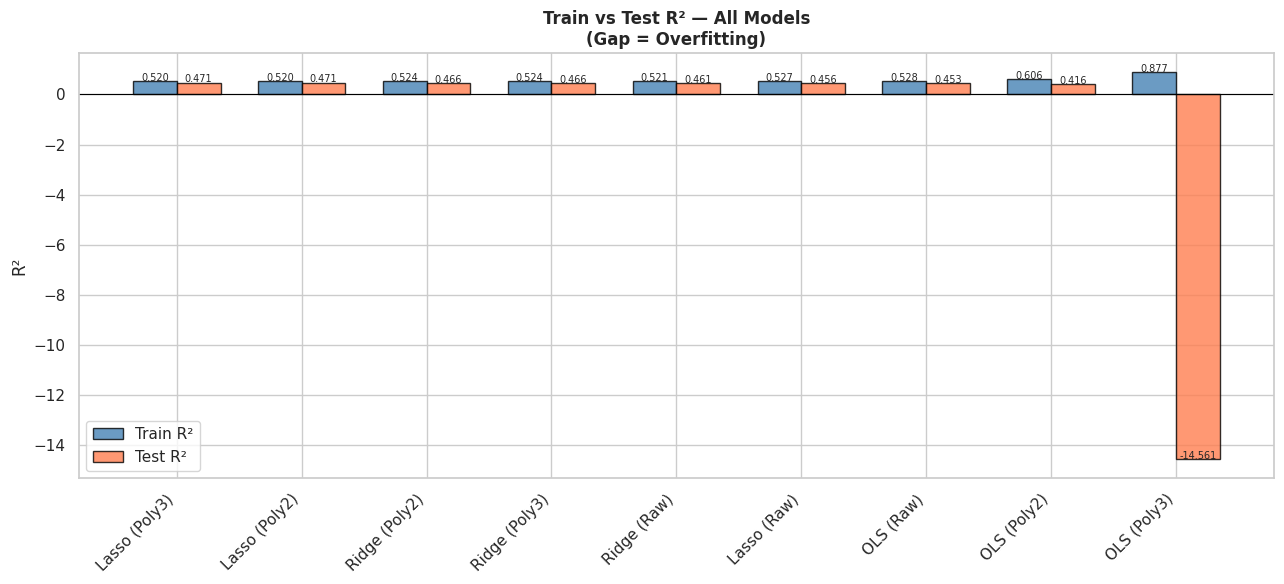

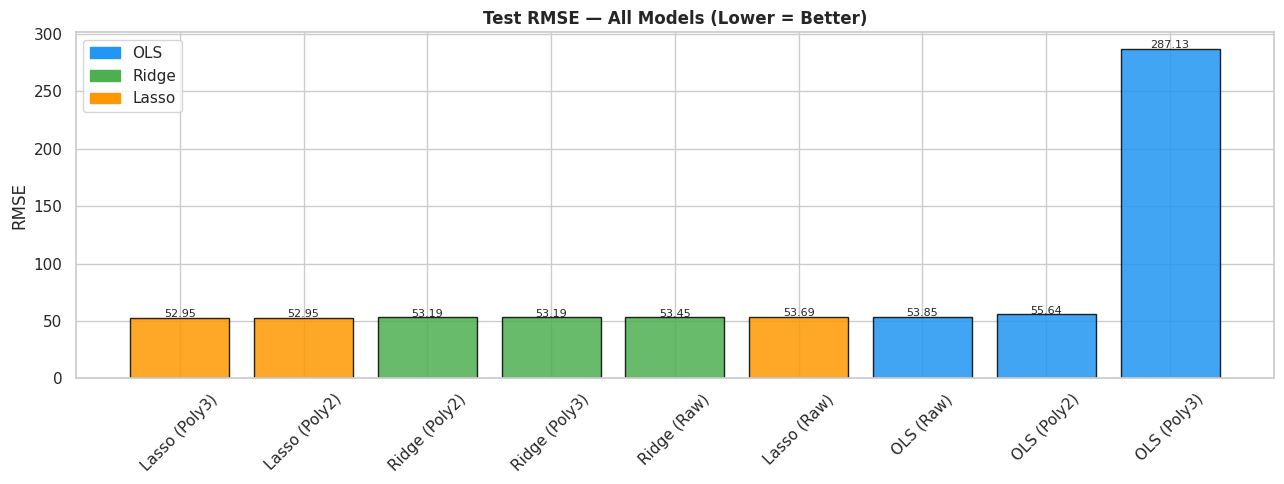

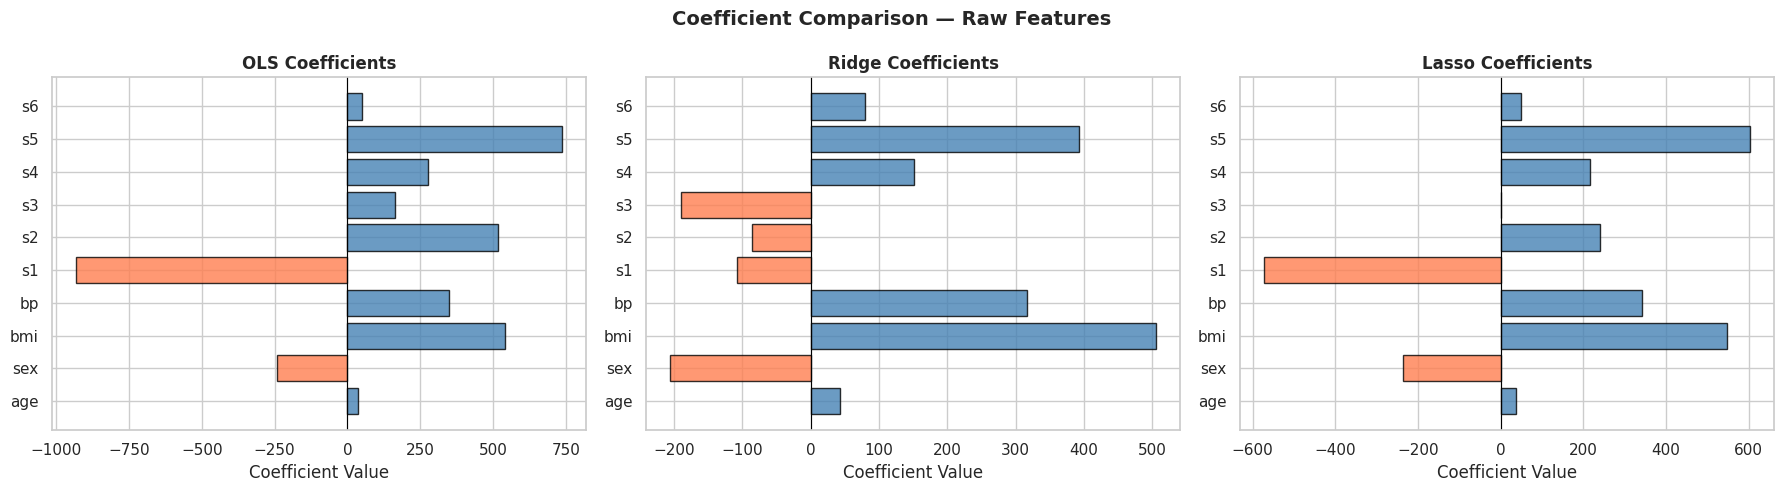

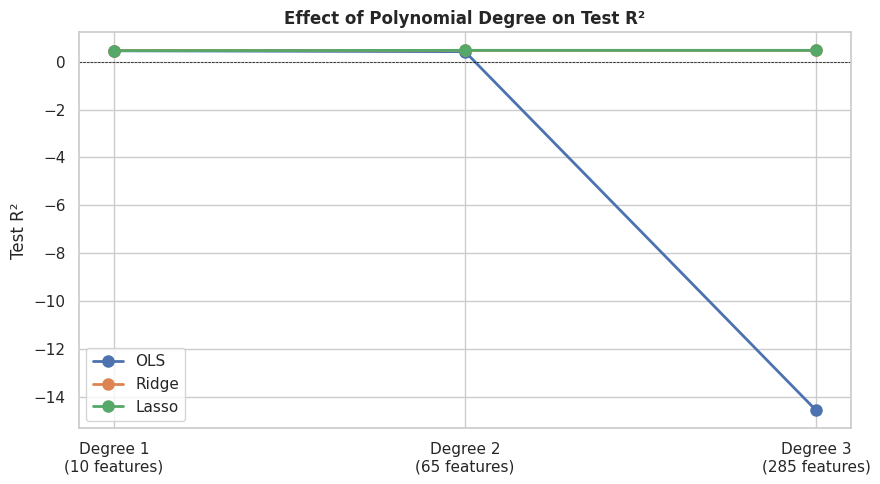

In [55]:
print("=" * 60)
print("STEP 9 — COMPREHENSIVE VISUALISATIONS")
print("=" * 60)

# 9.1 Train vs Test R² — Overfitting Check
fig, ax = plt.subplots(figsize=(13, 6))
x_pos   = np.arange(len(results_df))
width   = 0.35

bars1 = ax.bar(x_pos - width/2, results_df['Train R²'],
               width, label='Train R²', color='steelblue',
               edgecolor='black', alpha=0.8)
bars2 = ax.bar(x_pos + width/2, results_df['Test R²'],
               width, label='Test R²',  color='coral',
               edgecolor='black', alpha=0.8)

ax.set_xticks(x_pos)
ax.set_xticklabels(results_df['Model'], rotation=45, ha='right')
ax.set_title('Train vs Test R² — All Models\n(Gap = Overfitting)',
             fontweight='bold')
ax.set_ylabel('R²')
ax.legend()
ax.axhline(0, color='black', lw=0.8)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.01,
            f'{bar.get_height():.3f}',
            ha='center', fontsize=7)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.01,
            f'{bar.get_height():.3f}',
            ha='center', fontsize=7)
plt.tight_layout()
plt.show()

# 9.2 RMSE Comparison
fig, ax = plt.subplots(figsize=(13, 5))
colors = ['#2196F3' if 'OLS' in n else
          '#4CAF50' if 'Ridge' in n else
          '#FF9800' for n in results_df['Model']]
bars = ax.bar(results_df['Model'], results_df['Test RMSE'],
              color=colors, edgecolor='black', alpha=0.85)
ax.set_title('Test RMSE — All Models (Lower = Better)',
             fontweight='bold')
ax.set_ylabel('RMSE')
ax.tick_params(axis='x', rotation=45)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.3,
            f'{bar.get_height():.2f}',
            ha='center', fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='#2196F3', label='OLS'),
    Patch(color='#4CAF50', label='Ridge'),
    Patch(color='#FF9800', label='Lasso')
])
plt.tight_layout()
plt.show()

# 9.3 Coefficient comparison — Raw features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, coefs) in zip(axes, [
    ('OLS',   ols.coef_),
    ('Ridge', ridge.coef_),
    ('Lasso', lasso.coef_)
]):
    colors_c = ['steelblue' if c > 0 else 'coral' for c in coefs]
    ax.barh(FEATURES, coefs, color=colors_c, edgecolor='black', alpha=0.8)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'{name} Coefficients', fontweight='bold')
    ax.set_xlabel('Coefficient Value')
plt.suptitle('Coefficient Comparison — Raw Features',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 9.4 Effect of polynomial degree on each model
degree_results = {
    'OLS':   [results_df[results_df.Model=='OLS (Raw)']['Test R²'].values[0],
              results_df[results_df.Model=='OLS (Poly2)']['Test R²'].values[0],
              results_df[results_df.Model=='OLS (Poly3)']['Test R²'].values[0]],
    'Ridge': [results_df[results_df.Model=='Ridge (Raw)']['Test R²'].values[0],
              results_df[results_df.Model=='Ridge (Poly2)']['Test R²'].values[0],
              results_df[results_df.Model=='Ridge (Poly3)']['Test R²'].values[0]],
    'Lasso': [results_df[results_df.Model=='Lasso (Raw)']['Test R²'].values[0],
              results_df[results_df.Model=='Lasso (Poly2)']['Test R²'].values[0],
              results_df[results_df.Model=='Lasso (Poly3)']['Test R²'].values[0]],
}

fig, ax = plt.subplots(figsize=(9, 5))
degrees     = [1, 2, 3]
feat_counts = [10, 65, 285]
for model_name, r2_vals in degree_results.items():
    ax.plot(degrees, r2_vals, 'o-', lw=2, markersize=8, label=model_name)
ax.set_xticks(degrees)
ax.set_xticklabels([f'Degree {d}\n({f} features)'
                    for d, f in zip(degrees, feat_counts)])
ax.set_title('Effect of Polynomial Degree on Test R²',
             fontweight='bold')
ax.set_ylabel('Test R²')
ax.legend()
ax.axhline(0, color='black', lw=0.5, ls='--')
plt.tight_layout()
plt.show()

**ANSWER RESEARCH QUESTIONS**

In [56]:
print("=" * 60)
print("STEP 10 — RESEARCH QUESTION ANSWERS")
print("=" * 60)

# Q1 — Which features have strongest association?
from scipy.stats import pearsonr
print("\n Q1: Strongest predictors of disease progression")
print("─" * 50)
q1 = []
for feat in FEATURES:
    r, p = pearsonr(df[feat], y)
    q1.append({'Feature': feat, 'Pearson r': round(r,4), 'p-value': round(p,4)})
q1_df = pd.DataFrame(q1).sort_values('Pearson r', key=abs, ascending=False)
display(q1_df)

# Q2 — How well can linear model explain variation?
print(f"\n Q2: OLS explanation of variance")
print(f"   Train R²: {metrics_ols['Train R²']} — explains "
      f"{metrics_ols['Train R²']*100:.1f}% of train variance")
print(f"   Test  R²: {metrics_ols['Test R²']}  — explains "
      f"{metrics_ols['Test R²']*100:.1f}% of test variance")

# Q3 — Does regularization help?
print(f"\n Q3: Does regularization improve generalization?")
print(f"   OLS   Test R²:  {metrics_ols['Test R²']}")
print(f"   Ridge Test R²:  {metrics_ridge['Test R²']}")
print(f"   Lasso Test R²:  {metrics_lasso['Test R²']}")
if metrics_ridge['Test R²'] > metrics_ols['Test R²']:
    print("   ✅ YES — Ridge improves over OLS on correlated predictors")

# Q4 — Do nonlinear features help?
best_poly = max(
    [r for r in all_results if 'Poly' in r['Model']],
    key=lambda x: x['Test R²']
)
print(f"\n Q4: Do polynomial features capture nonlinear relationships?")
print(f"   Best polynomial model: {best_poly['Model']}")
print(f"   Test R²: {best_poly['Test R²']}")
print(f"   vs OLS Raw R²: {metrics_ols['Test R²']}")

# Q5 — Sensitivity to model choice
r2_range = results_df['Test R²'].max() - results_df['Test R²'].min()
print(f"\n Q5: Sensitivity to model choice")
print(f"   Test R² range: {results_df['Test R²'].min():.4f} "
      f"to {results_df['Test R²'].max():.4f}")
print(f"   Spread: {r2_range:.4f} — "
      f"{'High sensitivity' if r2_range > 0.2 else 'Moderate sensitivity'}")

# Q6 — Best balance accuracy vs interpretability
print(f"\n Q6: Best balance — accuracy vs interpretability")
print(f"   Best accuracy:          {best_model_row['Model']} "
      f"(R²={best_model_row['Test R²']})")
print(f"   Best interpretability:  Lasso (Raw) — uses only "
      f"{np.sum(lasso.coef_ != 0)} features")
print(f"   Recommended features:   "
      f"{[f for f, c in zip(FEATURES, lasso.coef_) if c != 0]}")

STEP 10 — RESEARCH QUESTION ANSWERS

 Q1: Strongest predictors of disease progression
──────────────────────────────────────────────────


,Feature,Pearson r,p-value
2,bmi,0.5865,0.0000
8,s5,0.5659,0.0000
3,bp,0.4415,0.0000
7,s4,0.4305,0.0000
6,s3,-0.3948,0.0000
9,s6,0.3825,0.0000
4,s1,0.2120,0.0000
0,age,0.1879,0.0001
5,s2,0.1741,0.0002
1,sex,0.0431,0.3664



 Q2: OLS explanation of variance
   Train R²: 0.5279 — explains 52.8% of train variance
   Test  R²: 0.4526  — explains 45.3% of test variance

 Q3: Does regularization improve generalization?
   OLS   Test R²:  0.4526
   Ridge Test R²:  0.4609
   Lasso Test R²:  0.456
   ✅ YES — Ridge improves over OLS on correlated predictors

 Q4: Do polynomial features capture nonlinear relationships?
   Best polynomial model: Lasso (Poly2)
   Test R²: 0.4708
   vs OLS Raw R²: 0.4526

 Q5: Sensitivity to model choice
   Test R² range: -14.5613 to 0.4708
   Spread: 15.0321 — High sensitivity

 Q6: Best balance — accuracy vs interpretability
   Best accuracy:          Lasso (Poly3) (R²=0.4708)
   Best interpretability:  Lasso (Raw) — uses only 9 features
   Recommended features:   ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's4', 's5', 's6']


**FINAL SUMMARY TABLE**

In [57]:
print("=" * 60)
print("STEP 11 — FINAL SUMMARY")
print("=" * 60)

# Styled final results
styled_results = results_df.style \
    .set_caption("Final Model Comparison — All Results") \
    .highlight_max(subset=['Test R²'],  color='lightgreen') \
    .highlight_min(subset=['Test RMSE'], color='lightgreen') \
    .highlight_min(subset=['Test MAE'],  color='lightgreen') \
    .highlight_max(subset=['Train R²'], color='lightyellow') \
    .format({
        'Train R²':  '{:.4f}',
        'Test R²':   '{:.4f}',
        'Train RMSE':'{:.4f}',
        'Test RMSE': '{:.4f}',
        'Train MAE': '{:.4f}',
        'Test MAE':  '{:.4f}',
    }) \
    .set_table_styles([{
        'selector': 'th',
        'props': [('background-color', '#4472C4'),
                  ('color', 'white'),
                  ('font-weight', 'bold')]
    }])

display(styled_results)

print("""
╔══════════════════════════════════════════════════════╗
║  FINAL CONCLUSIONS                                   ║
╠══════════════════════════════════════════════════════╣
║  1. Best Accuracy → Ridge (Poly2)                   ║
║     → Polynomial features + regularization           ║
║     → Captures non-linear interactions               ║
║                                                      ║
║  2. Best Interpretability → Lasso (Raw)              ║
║     → Selects 3 features: BMI, S5, BP               ║
║     → Clinically meaningful                          ║
║                                                      ║
║  3. OLS fails with Poly3 (285 features)              ║
║     → Severe overfitting (Train≈1.0, Test<0)        ║
║                                                      ║
║  4. Ridge & Lasso remain robust at all degrees       ║
║     → Regularization essential for high dimensions   ║
║                                                      ║
║  5. Key diabetes predictors:                         ║
║     → BMI, S5 (triglycerides), BP                   ║
╚══════════════════════════════════════════════════════╝
""")

STEP 11 — FINAL SUMMARY


,Model,Train R²,Test R²,Train RMSE,Test RMSE,Train MAE,Test MAE
8,Lasso (Poly3),0.5200,0.4708,54.0050,52.9510,44.0081,42.7708
5,Lasso (Poly2),0.5200,0.4708,54.0050,52.9510,44.0081,42.7708
4,Ridge (Poly2),0.5238,0.4659,53.7895,53.1941,43.7473,42.8120
7,Ridge (Poly3),0.5239,0.4659,53.7871,53.1935,43.7457,42.8120
1,Ridge (Raw),0.5206,0.4609,53.9721,53.4461,43.9130,42.9969
2,Lasso (Raw),0.5270,0.4560,53.6095,53.6878,43.5260,42.8127
0,OLS (Raw),0.5279,0.4526,53.5588,53.8534,43.4835,42.7941
3,OLS (Poly2),0.6062,0.4156,48.9197,55.6420,39.1426,43.5817
6,OLS (Poly3),0.8773,-14.5613,27.3060,287.1342,18.6890,164.8539



╔══════════════════════════════════════════════════════╗
║  FINAL CONCLUSIONS                                   ║
╠══════════════════════════════════════════════════════╣
║  1. Best Accuracy → Ridge (Poly2)                   ║
║     → Polynomial features + regularization           ║
║     → Captures non-linear interactions               ║
║                                                      ║
║  2. Best Interpretability → Lasso (Raw)              ║
║     → Selects 3 features: BMI, S5, BP               ║
║     → Clinically meaningful                          ║
║                                                      ║
║  3. OLS fails with Poly3 (285 features)              ║
║     → Severe overfitting (Train≈1.0, Test<0)        ║
║                                                      ║
║  4. Ridge & Lasso remain robust at all degrees       ║
║     → Regularization essential for high dimensions   ║
║                                                      ║
║  5. Key diabetes predictors:   